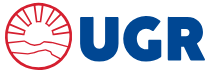

**Trabajo Final** - Ariel Fernandez  : *Clasificación del riesgo de derivación a Gestión Judicial en una cartera de préstamos personales mediante aprendizaje automático supervisado*
# Elección del algoritmo para clasificar el riesgo de gestión judicial

Se comparan Regresión Logística, Random Forest y XGBoost con préstamos otorgados en 2024–2025 cuyo desenlace es conocido.

Los préstamos activos y las operaciones de 2026 quedan excluidos

Tras elegir el algoritmo, se ajustan sus parámetros, pesos y umbrales por separado para Apertura y Renovación.

## Indice metodológico

1. Leer el dataset desde Google Drive.
2. Trabajar con los préstamos otorgados en **2024–2025** cuyo desenlace es conocido.
3. Definir la variable objetivo:
   - `2` y `5` = Judicial (`1`).
   - `3` y `4` = No Judicial (`0`).
   - `1` = Activo; se excluye de esta etapa.
4. Separar **Apertura** y **Renovación**.
5. Dividir Train y Test por `id_cliente`.
6. Analizar el desbalance de clases en Train.
7. Calcular un peso inicial por población: `No Judicial / Judicial`.
8. Comparar los algoritmos Regresión Logística, Random Forest y XGBoost.
9. Aplicar la misma relación de pesos a los tres algoritmos dentro de cada población.
10. Comparar distintas configuraciones de los tres algoritmos mediante las mismas particiones de validación cruzada y seleccionar el de mayor PR-AUC.
11. Tras elegir XGBoost, prueba configuraciones de sus parámetros por separado para Apertura y Renovación.
12. Evaluar el ajuste de XGBoost con los pesos iniciales de Apertura y Renovación mediante validación cruzada.
13. Evaluar los pesos de la clase Judicial para Apertura y Renovación.
14. Evaluar distintos umbrales de clasificación para Apertura y Renovación.
15. Mostrar recall, precisión, F1, F2, VP, FN, FP y VN.
16. Seleccionar el peso y el umbral para Apertura y Renovación a partir de los resultados de la evaluación.
17. Exportar los resultados de la comparación y del ajuste de XGBoost.
18. Definir la configuración inicial de XGBoost para Apertura y Renovación antes de evaluarla en Test.
19. Analizar la distribución de Judicial y No Judicial por población y rango de score.
20. Probar pesos para la clase Judicial según población y rango de score.
21. Comparar los pesos generales y los pesos segmentados mediante validación cruzada sobre Train.
22. Evaluar distintos pesos de la clase Judicial en Renovación con score de 800 o más.
23. Definir los pesos segmentados finales para Apertura y Renovación.
24. Comparar en Test la configuración de pesos generales con la de pesos segmentados.
25. Calcular la importancia relativa de las variables del XGBoost final para Apertura y Renovación.
26. Evaluar en Renovación el aporte del historial crediticio mediante una comparación con y sin esas variables.
27. Exportar las configuraciones y los resultados finales del análisis.



## Preparación del entorno: instalación e importaciones


In [ ]:
!pip -q install xgboost openpyxl joblib

import warnings, gc
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, fbeta_score,
    balanced_accuracy_score, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 200)

RANDOM_STATE = 42
N_SPLITS_TEST = 4
N_SPLITS_CV = 3

# Solo como referencia operativa común para comparar los 3 modelos.
# NO es el umbral final.
UMBRAL_REFERENCIA = 0.40


## 1. Cargar el dataset desde Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

RUTA_BASE = Path('/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/dataset2326v2.xlsx')
RUTA_SALIDA = Path('/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/RESULTADOS_V2_XGBOOST_AJUSTE_FINO_PESOS_UMBRALES.xlsx')

if not RUTA_BASE.exists():
    raise FileNotFoundError(
        f'No se encontró {RUTA_BASE}. '
        'Asegúrate de que el archivo existe en tu Google Drive y que la ruta es correcta.'
    )

df = pd.read_excel(RUTA_BASE)
df.columns = [str(c).strip() for c in df.columns]

print('Base general:', df.shape)
print(
    'Años disponibles:',
    sorted(pd.to_numeric(df['añofac'], errors='coerce').dropna().unique().tolist())
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base general: (48668, 40)
Años disponibles: [2023, 2024, 2025, 2026]


## 2–3. Delimitar el período y definir la variable objetivo


In [ ]:
d = df[pd.to_numeric(df['añofac'], errors='coerce').between(2024, 2025)].copy()

d['judicial_bin'] = np.where(
    d['target'].isin([2, 5]), 1,
    np.where(d['target'].isin([3, 4]), 0, np.nan)
)

conteo_target = (
    d['target']
    .value_counts(dropna=False)
    .rename_axis('target')
    .reset_index(name='cantidad')
    .sort_values('target', na_position='last')
)

display(conteo_target)
print('target=6 presentes en V2 2024-2025:', int((d['target'] == 6).sum()))

historico = d[d['judicial_bin'].notna()].copy()
historico['judicial_bin'] = historico['judicial_bin'].astype(int)

# Feature derivada disponible al otorgamiento
sueldo = pd.to_numeric(historico['SUELDO'], errors='coerce')
cuota = pd.to_numeric(historico['monto_cuota'], errors='coerce')

historico['relacion_cuota_ingreso'] = np.where(
    sueldo > 0,
    cuota / sueldo * 100,
    np.nan
)

tipo = historico['tipocredito'].astype(str).str.upper().str.strip()

poblaciones = {
    'Apertura': historico[tipo.str.contains('APERTURA', na=False)].copy(),
    'Renovación': historico[tipo.str.contains('RENOV', na=False)].copy()
}

print('Apertura:', poblaciones['Apertura'].shape)
print('Renovación:', poblaciones['Renovación'].shape)

,target,cantidad
2,1,4640
1,2,9779
3,3,2692
0,4,12765
4,5,58


target=6 presentes en V2 2024-2025: 0
Apertura: (10797, 42)
Renovación: (14497, 42)


## 4. Separar Apertura y Renovación y definir sus variables


In [ ]:
VARIABLES = {
    'Apertura': [
        'rscore',
        'capitalprestado',
        'plan',
        'SUELDO',
        'interes',
        'totalfac',
        'costo_credito',
        'monto_cuota',
        'actividad',
        'rangoedad',
        'genero',
        'provincia',
        'sucursal',
        'relacion_cuota_ingreso'
    ],
    'Renovación': [
        'SUELDO',
        'monto_cuota',
        'rscore',
        'capitalprestado',
        'plan',
        'interes',
        'totalfac',
        'costo_credito',
        'actividad',
        'rangoedad',
        'genero',
        'provincia',
        'sucursal',
        'relacion_cuota_ingreso',
        'antiguedad_credito',
        'cantidad_prestamos_anteriores',
        'tuvo_mora_anterior',
        'max_mora_prestamos_anteriores',
        'prestamos_cancelados_normal',
        'prestamos_en_judicial_anteriores'
    ]
}

for nombre, vars_ in VARIABLES.items():
    faltantes = [v for v in vars_ if v not in poblaciones[nombre].columns]
    if faltantes:
        raise KeyError(f'{nombre}: faltan variables en la base: {faltantes}')
    print(f'{nombre}: {len(vars_)} variables')

Apertura: 14 variables
Renovación: 20 variables


## 5. Dividir Train y Test por cliente

El Test queda reservado.  
La comparación, el ajuste de pesos y el análisis de umbrales se hacen dentro de **Train/OOF**.

### Guardar y reutilizar las particiones

La primera ejecución guarda Train/Test y las particiones de validación cruzada por población. Las siguientes recuperan esa separación. Si cambia la base o su orden, el código se detiene para evitar sustituirla. Esto fija la separación a partir de la primera ejecución con este guardado; no recupera por sí solo una ejecución anterior.


In [ ]:
import json
import hashlib
import os

RUTA_GUARDADO_02 = RUTA_BASE.parent / 'EJECUCIONES_CODIGO_02'
RUTA_GUARDADO_02.mkdir(parents=True, exist_ok=True)
RUTA_PARTICIONES_02 = RUTA_GUARDADO_02 / 'particiones_train_test.json'
RUTA_FOLDS_02 = RUTA_GUARDADO_02 / 'particiones_validacion_cruzada.json'


def huella_datos_02(datos):
    # Comprobar contenido y orden antes de reutilizar posiciones guardadas.
    valores = pd.util.hash_pandas_object(datos, index=True).to_numpy()
    contenido = valores.tobytes() + repr(list(datos.columns)).encode('utf-8')
    return hashlib.sha256(contenido).hexdigest()


def leer_json_02(ruta):
    if not ruta.exists():
        return {}
    return json.loads(ruta.read_text(encoding='utf-8'))


def escribir_json_02(ruta, contenido):
    temporal = ruta.with_suffix('.tmp')
    temporal.write_text(json.dumps(contenido, ensure_ascii=False, indent=2), encoding='utf-8')
    temporal.replace(ruta)


def validar_indices_02(train, test, n, grupos):
    train = np.asarray(train, dtype=int)
    test = np.asarray(test, dtype=int)
    if len(np.unique(train)) != len(train) or len(np.unique(test)) != len(test):
        raise ValueError('Hay índices duplicados en las particiones guardadas.')
    unidos = np.concatenate([train, test])
    if len(unidos) != n or not np.array_equal(np.sort(unidos), np.arange(n)):
        raise ValueError('Las particiones guardadas no cubren exactamente esta población.')
    if set(grupos.iloc[train]) & set(grupos.iloc[test]):
        raise ValueError('Un cliente aparece en entrenamiento y evaluación dentro de la misma población.')
    return train, test


def recuperar_o_crear_particion_02(nombre, datos, variables, splitter):
    archivo = leer_json_02(RUTA_PARTICIONES_02)
    huella = huella_datos_02(datos[list(variables) + ['judicial_bin', 'id_cliente']])
    if nombre in archivo:
        entrada = archivo[nombre]
        if entrada['huella'] != huella:
            raise ValueError(f'{nombre}: cambió la base, el orden o las variables. No se reemplazarán las particiones guardadas.')
        train, test = entrada['train'], entrada['test']
        print(f'{nombre}: se recuperó la división Train/Test guardada.')
    else:
        train, test = next(splitter.split(datos[variables], datos['judicial_bin'], groups=datos['id_cliente']))
        archivo[nombre] = {'huella': huella, 'train': train.tolist(), 'test': test.tolist()}
        # Validar antes de guardar.
        validar_indices_02(train, test, len(datos), datos['id_cliente'])
        escribir_json_02(RUTA_PARTICIONES_02, archivo)
        print(f'{nombre}: se creó y guardó la división Train/Test por primera vez.')
    return validar_indices_02(train, test, len(datos), datos['id_cliente'])


def recuperar_o_crear_folds_02(nombre, s, cv):
    archivo = leer_json_02(RUTA_FOLDS_02)
    referencia = s['X_train'].copy()
    referencia['__resultado__'] = s['y_train'].to_numpy()
    referencia['__cliente__'] = s['groups_train'].to_numpy()
    huella = huella_datos_02(referencia)
    if nombre in archivo:
        entrada = archivo[nombre]
        if entrada['huella'] != huella:
            raise ValueError(f'{nombre}: Train no coincide con las particiones CV guardadas.')
        folds = entrada['folds']
        print(f'{nombre}: se recuperaron las particiones de validación cruzada guardadas.')
    else:
        folds = [(a.tolist(), b.tolist()) for a, b in cv.split(s['X_train'], s['y_train'], groups=s['groups_train'])]
    if len(folds) != N_SPLITS_CV:
        raise ValueError('No coincide el número de particiones de validación cruzada.')
    validados = [validar_indices_02(a, b, len(referencia), s['groups_train']) for a, b in folds]
    evaluados = np.concatenate([b for a, b in validados])
    if not np.array_equal(np.sort(evaluados), np.arange(len(referencia))):
        raise ValueError('Cada operación debe evaluarse exactamente una vez en OOF.')
    if nombre not in archivo:
        archivo[nombre] = {'huella': huella, 'folds': folds}
        escribir_json_02(RUTA_FOLDS_02, archivo)
        print(f'{nombre}: se guardaron las particiones de validación cruzada.')
    return validados


In [ ]:
def dividir_por_cliente(datos, variables, nombre):
    X = datos[variables].copy()
    y = datos['judicial_bin'].astype(int).copy()
    grupos = datos['id_cliente'].copy()

    splitter = StratifiedGroupKFold(
        n_splits=N_SPLITS_TEST,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    idx_train, idx_test = recuperar_o_crear_particion_02(
        nombre, datos, variables, splitter
    )

    return {
        'X_train': X.iloc[idx_train].copy(),
        'X_test': X.iloc[idx_test].copy(),
        'y_train': y.iloc[idx_train].copy(),
        'y_test': y.iloc[idx_test].copy(),
        'groups_train': grupos.iloc[idx_train].copy(),
        'groups_test': grupos.iloc[idx_test].copy(),
        'idx_train': idx_train,
        'idx_test': idx_test
    }

divisiones = {
    nombre: dividir_por_cliente(datos, VARIABLES[nombre], nombre)
    for nombre, datos in poblaciones.items()
}

for nombre, s in divisiones.items():
    tabla = pd.DataFrame({
        'Conjunto': ['Train', 'Test'],
        'Préstamos': [len(s['y_train']), len(s['y_test'])],
        'Judiciales': [int(s['y_train'].sum()), int(s['y_test'].sum())],
        'No judiciales': [
            int((s['y_train'] == 0).sum()),
            int((s['y_test'] == 0).sum())
        ],
        'Tasa judicial': [s['y_train'].mean(), s['y_test'].mean()],
        'Clientes únicos': [
            s['groups_train'].nunique(),
            s['groups_test'].nunique()
        ]
    })
    print('\n', nombre)
    display(tabla.style.format({'Tasa judicial':'{:.2%}'}).hide(axis='index'))

Apertura: se recuperó la división Train/Test guardada.
Renovación: se recuperó la división Train/Test guardada.

 Apertura


Conjunto,Préstamos,Judiciales,No judiciales,Tasa judicial,Clientes únicos
Train,8098,4552,3546,56.21%,8098
Test,2699,1510,1189,55.95%,2699



 Renovación


Conjunto,Préstamos,Judiciales,No judiciales,Tasa judicial,Clientes únicos
Train,10895,2810,8085,25.79%,7053
Test,3602,965,2637,26.79%,2353


## 6–7. Analizar el desbalance y calcular los pesos iniciales

El peso se calcula **solo con Train**:

\[
peso_{judicial} = \frac{N_{No\ Judicial}}{N_{Judicial}}
\]

Dentro de una misma población, Regresión Logística, Random Forest y XGBoost reciben la **misma relación de peso entre clases**.

- Clase 0 (No judicial): peso relativo = 1.
- Clase 1 (Judicial): peso relativo = `n0 / n1`.

La implementación cambia según el algoritmo, pero la decisión de balanceo es la misma.

In [ ]:
PESO_ESTANDAR = {}
filas_balanceo = []

for nombre, s in divisiones.items():
    n1 = int((s['y_train'] == 1).sum())
    n0 = int((s['y_train'] == 0).sum())
    peso = n0 / n1

    PESO_ESTANDAR[nombre] = peso

    filas_balanceo.append({
        'Población': nombre,
        'Train': len(s['y_train']),
        'No judicial': n0,
        'Judicial': n1,
        'Tasa judicial': n1 / len(s['y_train']),
        'Peso estándar judicial (n0/n1)': peso
    })

tabla_balanceo = pd.DataFrame(filas_balanceo)

display(
    tabla_balanceo.style.format({
        'Tasa judicial':'{:.2%}',
        'Peso estándar judicial (n0/n1)':'{:.4f}'
    }).hide(axis='index')
)

print('\nPesos estándar calculados desde Train:')
for pob, peso in PESO_ESTANDAR.items():
    print(f'  {pob}: {peso:.4f}')

Población,Train,No judicial,Judicial,Tasa judicial,Peso estándar judicial (n0/n1)
Apertura,8098,3546,4552,56.21%,0.7790
Renovación,10895,8085,2810,25.79%,2.8772



Pesos estándar calculados desde Train:
  Apertura: 0.7790
  Renovación: 2.8772


## Preparar las variables para los algoritmos


In [ ]:
def columnas_por_tipo(datos, variables):
    cat = []
    num = []

    for c in variables:
        # Sucursal se trata como categórica aunque venga numérica.
        if c == 'sucursal' or not pd.api.types.is_numeric_dtype(datos[c]):
            cat.append(c)
        else:
            num.append(c)

    return num, cat


def construir_preprocesador(datos, variables, escalar_numericas=False):
    num, cat = columnas_por_tipo(datos, variables)

    pasos_num = [('imputar', SimpleImputer(strategy='median'))]
    if escalar_numericas:
        pasos_num.append(('escalar', StandardScaler()))

    pipe_num = Pipeline(pasos_num)

    pipe_cat = Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    return ColumnTransformer(
        transformers=[
            ('num', pipe_num, num),
            ('cat', pipe_cat, cat)
        ],
        remainder='drop'
    )

## 8. Definir los tres algoritmos con la misma relación de pesos

No se usa `balanced` ni `balanced_subsample`.

La relación de pesos fue decidida previamente a partir de Train y se pasa explícitamente a los tres modelos.

In [ ]:
ALGORITMOS = [
    'Regresión Logística',
    'Random Forest',
    'XGBoost'
]

def crear_modelo(algoritmo, poblacion):
    peso = PESO_ESTANDAR[poblacion]

    if algoritmo == 'Regresión Logística':
        modelo = LogisticRegression(
            max_iter=3000,
            class_weight={0: 1.0, 1: peso},
            random_state=RANDOM_STATE
        )
        return modelo, True

    if algoritmo == 'Random Forest':
        modelo = RandomForestClassifier(
            class_weight={0: 1.0, 1: peso},
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        return modelo, False

    if algoritmo == 'XGBoost':
        modelo = XGBClassifier(
            scale_pos_weight=peso,
            objective='binary:logistic',
            eval_metric='logloss',
            tree_method='hist',
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        return modelo, False

    raise ValueError(algoritmo)


def espacio_parametros(algoritmo):
    if algoritmo == 'Regresión Logística':
        return {
            'modelo__C': [0.03,0.05,0.1,0.3,0.5,1,3,5],
            'modelo__solver': ['liblinear','lbfgs']
        }

    if algoritmo == 'Random Forest':
        return {
            'modelo__n_estimators': [250,400,600],
            'modelo__max_depth': [None,6,10,14],
            'modelo__min_samples_leaf': [1,2,5,10],
            'modelo__max_features': ['sqrt',0.5,0.8]
        }

    if algoritmo == 'XGBoost':
        return {
            'modelo__n_estimators': [300,500,700],
            'modelo__max_depth': [2,3,4,5],
            'modelo__learning_rate': [0.03,0.05,0.08,0.10],
            'modelo__subsample': [0.7,0.85,1.0],
            'modelo__colsample_bytree': [0.7,0.85,1.0],
            'modelo__min_child_weight': [1,3,5],
            'modelo__reg_lambda': [1,3,5]
        }

    raise ValueError(algoritmo)


N_ITER = {
    'Regresión Logística': 8,
    'Random Forest': 8,
    'XGBoost': 12
}

## 9. Comparar los algoritmos con los mismos pesos y particiones

- Mismo Train.
- Mismos folds.
- Mismas variables dentro de cada población.
- Mismo balanceo relativo dentro de cada población.
- Ajuste por **PR-AUC**.
- Todavía no se ajustan pesos específicos de XGBoost.
Un **fold** es una partición de los datos de entrenamiento utilizada en la validación cruzada. En este notebook, Train se divide en **tres partes**: el modelo aprende con dos y se evalúa con la tercera. El proceso se repite cambiando la parte utilizada para evaluar. El **PR-AUC CV** resume el desempeño obtenido en esas evaluaciones; PR-AUC analiza la relación entre precisión y recall de la clase Judicial. Las particiones se agrupan por cliente para que sus operaciones no queden repartidas entre entrenamiento y evaluación.


In [ ]:
# Particiones fijas para evaluar los tres algoritmos
# sobre exactamente las mismas particiones de Train.
FOLDS_CV = {}

for nombre, s in divisiones.items():
    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS_CV,
        shuffle=True,
        random_state=52
    )
    FOLDS_CV[nombre] = recuperar_o_crear_folds_02(nombre, s, cv)

busquedas = {}
filas_comparacion_cv = []

for nombre in ['Apertura', 'Renovación']:
    s = divisiones[nombre]
    variables = VARIABLES[nombre]

    for algoritmo in ALGORITMOS:
        print(f'Ajustando {nombre} — {algoritmo}')

        estimador, escalar = crear_modelo(algoritmo, nombre)

        pipe = Pipeline([
            (
                'pre',
                construir_preprocesador(
                    s['X_train'],
                    variables,
                    escalar_numericas=escalar
                )
            ),
            ('modelo', estimador)
        ])

        search = RandomizedSearchCV(
            estimator=pipe,
            param_distributions=espacio_parametros(algoritmo),
            n_iter=N_ITER[algoritmo],
            scoring='average_precision',
            cv=FOLDS_CV[nombre],
            random_state=RANDOM_STATE,
            n_jobs=-1,
            refit=True,
            return_train_score=False
        )

        search.fit(s['X_train'], s['y_train'])

        busquedas[(nombre, algoritmo)] = search

        best_idx = search.best_index_
        filas_comparacion_cv.append({
            'Población': nombre,
            'Algoritmo': algoritmo,
            'Peso estándar usado': PESO_ESTANDAR[nombre],
            'PR-AUC CV': search.best_score_,
            'PR-AUC SD': search.cv_results_['std_test_score'][best_idx],
            'Mejores parámetros': str(search.best_params_)
        })

        print(
            f"  PR-AUC CV={search.best_score_:.4f} "
            f"± {search.cv_results_['std_test_score'][best_idx]:.4f}"
        )
        gc.collect()

tabla_comparacion_cv = (
    pd.DataFrame(filas_comparacion_cv)
    .sort_values(['Población','PR-AUC CV'], ascending=[True,False])
)

display(
    tabla_comparacion_cv.style.format({
        'Peso estándar usado':'{:.4f}',
        'PR-AUC CV':'{:.4f}',
        'PR-AUC SD':'{:.4f}'
    }).hide(axis='index')
)

Apertura: se recuperaron las particiones de validación cruzada guardadas.
Renovación: se recuperaron las particiones de validación cruzada guardadas.
Ajustando Apertura — Regresión Logística
  PR-AUC CV=0.8426 ± 0.0017
Ajustando Apertura — Random Forest
  PR-AUC CV=0.8439 ± 0.0039
Ajustando Apertura — XGBoost
  PR-AUC CV=0.8545 ± 0.0018
Ajustando Renovación — Regresión Logística
  PR-AUC CV=0.7633 ± 0.0091
Ajustando Renovación — Random Forest
  PR-AUC CV=0.7620 ± 0.0108
Ajustando Renovación — XGBoost
  PR-AUC CV=0.7705 ± 0.0078


Población,Algoritmo,Peso estándar usado,PR-AUC CV,PR-AUC SD,Mejores parámetros
Apertura,XGBoost,0.7790,0.8545,0.0018,"{'modelo__subsample': 1.0, 'modelo__reg_lambda': 3, 'modelo__n_estimators': 700, 'modelo__min_child_weight': 5, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.1, 'modelo__colsample_bytree': 0.7}"
Apertura,Random Forest,0.7790,0.8439,0.0039,"{'modelo__n_estimators': 400, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.5, 'modelo__max_depth': None}"
Apertura,Regresión Logística,0.7790,0.8426,0.0017,"{'modelo__solver': 'liblinear', 'modelo__C': 5}"
Renovación,XGBoost,2.8772,0.7705,0.0078,"{'modelo__subsample': 0.7, 'modelo__reg_lambda': 5, 'modelo__n_estimators': 500, 'modelo__min_child_weight': 1, 'modelo__max_depth': 5, 'modelo__learning_rate': 0.05, 'modelo__colsample_bytree': 1.0}"
Renovación,Regresión Logística,2.8772,0.7633,0.0091,"{'modelo__solver': 'lbfgs', 'modelo__C': 0.1}"
Renovación,Random Forest,2.8772,0.7620,0.0108,"{'modelo__n_estimators': 400, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.5, 'modelo__max_depth': None}"


### 10. Comparar predicciones fuera de muestra

Se usa `0,40` como umbral referencial  para observar Recall, Precisión, F2, FN y FP.

**0,40 NO se considera el mejor umbral ni el umbral final.**

In [ ]:
def metricas_binarias(y, proba, umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

    return {
        'PR-AUC': average_precision_score(y, proba),
        'ROC-AUC': roc_auc_score(y, proba),
        'Precisión': precision_score(y, pred, zero_division=0),
        'Recall': recall_score(y, pred, zero_division=0),
        'F1': f1_score(y, pred, zero_division=0),
        'F2': fbeta_score(y, pred, beta=2, zero_division=0),
        'Exactitud balanceada': balanced_accuracy_score(y, pred),
        'VP': int(tp),
        'FN': int(fn),
        'FP': int(fp),
        'VN': int(tn)
    }


oof_por_modelo = {}
filas_oof = []

for nombre in ['Apertura','Renovación']:
    s = divisiones[nombre]

    for algoritmo in ALGORITMOS:
        base = busquedas[(nombre, algoritmo)].best_estimator_
        oof = np.zeros(len(s['y_train']), dtype=float)

        for idx_tr, idx_val in FOLDS_CV[nombre]:
            modelo = clone(base)
            modelo.fit(
                s['X_train'].iloc[idx_tr],
                s['y_train'].iloc[idx_tr]
            )
            oof[idx_val] = modelo.predict_proba(
                s['X_train'].iloc[idx_val]
            )[:,1]

        oof_por_modelo[(nombre, algoritmo)] = oof

        met = metricas_binarias(
            s['y_train'].values,
            oof,
            UMBRAL_REFERENCIA
        )

        filas_oof.append({
            'Población': nombre,
            'Algoritmo': algoritmo,
            'Peso estándar usado': PESO_ESTANDAR[nombre],
            'Umbral referencia': UMBRAL_REFERENCIA,
            **met
        })

tabla_oof_3 = (
    pd.DataFrame(filas_oof)
    .sort_values(
        ['Población','PR-AUC','F2'],
        ascending=[True,False,False]
    )
)

display(
    tabla_oof_3.style.format({
        'Peso estándar usado':'{:.4f}',
        'Umbral referencia':'{:.2f}',
        'PR-AUC':'{:.4f}',
        'ROC-AUC':'{:.4f}',
        'Precisión':'{:.2%}',
        'Recall':'{:.2%}',
        'F1':'{:.4f}',
        'F2':'{:.4f}',
        'Exactitud balanceada':'{:.4f}'
    }).hide(axis='index')
)

Población,Algoritmo,Peso estándar usado,Umbral referencia,PR-AUC,ROC-AUC,Precisión,Recall,F1,F2,Exactitud balanceada,VP,FN,FP,VN
Apertura,XGBoost,0.7790,0.40,0.8541,0.8164,73.52%,82.05%,0.7755,0.8019,0.7206,3735,817,1345,2201
Apertura,Random Forest,0.7790,0.40,0.8437,0.8052,71.07%,84.34%,0.7713,0.8130,0.7013,3839,713,1563,1983
Apertura,Regresión Logística,0.7790,0.40,0.8424,0.8049,72.95%,82.23%,0.7731,0.8019,0.7154,3743,809,1388,2158
Renovación,XGBoost,2.8772,0.40,0.7702,0.8759,57.20%,78.47%,0.6617,0.7304,0.7903,2205,605,1650,6435
Renovación,Regresión Logística,2.8772,0.40,0.7628,0.8739,52.20%,83.13%,0.6413,0.7432,0.7834,2336,474,2139,5946
Renovación,Random Forest,2.8772,0.40,0.7610,0.8695,60.68%,72.88%,0.6622,0.7007,0.7823,2048,762,1327,6758


### 10.1. Ordenar los algoritmos por PR-AUC CV

Esta tabla **no modifica ningún modelo**.  
Solo resume cuál quedó primero por PR-AUC CV en cada población.

La decisión final del algoritmo ganador se toma después de revisar la comparación.

In [ ]:
ranking = tabla_comparacion_cv.copy()
ranking['Ranking PR-AUC'] = (
    ranking.groupby('Población')['PR-AUC CV']
    .rank(method='min', ascending=False)
    .astype(int)
)

display(
    ranking.sort_values(['Población','Ranking PR-AUC'])
    .style.format({
        'Peso estándar usado':'{:.4f}',
        'PR-AUC CV':'{:.4f}',
        'PR-AUC SD':'{:.4f}'
    }).hide(axis='index')
)

print('\nMejor PR-AUC CV por población:')
for nombre in ['Apertura','Renovación']:
    mejor = (
        ranking[ranking['Población'] == nombre]
        .sort_values('PR-AUC CV', ascending=False)
        .iloc[0]
    )
    print(
        f"  {nombre}: {mejor['Algoritmo']} "
        f"(PR-AUC CV={mejor['PR-AUC CV']:.4f})"
    )

Población,Algoritmo,Peso estándar usado,PR-AUC CV,PR-AUC SD,Mejores parámetros,Ranking PR-AUC
Apertura,XGBoost,0.7790,0.8545,0.0018,"{'modelo__subsample': 1.0, 'modelo__reg_lambda': 3, 'modelo__n_estimators': 700, 'modelo__min_child_weight': 5, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.1, 'modelo__colsample_bytree': 0.7}",1
Apertura,Random Forest,0.7790,0.8439,0.0039,"{'modelo__n_estimators': 400, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.5, 'modelo__max_depth': None}",2
Apertura,Regresión Logística,0.7790,0.8426,0.0017,"{'modelo__solver': 'liblinear', 'modelo__C': 5}",3
Renovación,XGBoost,2.8772,0.7705,0.0078,"{'modelo__subsample': 0.7, 'modelo__reg_lambda': 5, 'modelo__n_estimators': 500, 'modelo__min_child_weight': 1, 'modelo__max_depth': 5, 'modelo__learning_rate': 0.05, 'modelo__colsample_bytree': 1.0}",1
Renovación,Regresión Logística,2.8772,0.7633,0.0091,"{'modelo__solver': 'lbfgs', 'modelo__C': 0.1}",2
Renovación,Random Forest,2.8772,0.7620,0.0108,"{'modelo__n_estimators': 400, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.5, 'modelo__max_depth': None}",3



Mejor PR-AUC CV por población:
  Apertura: XGBoost (PR-AUC CV=0.8545)
  Renovación: XGBoost (PR-AUC CV=0.7705)


## 11. Ajustar los parámetros de XGBoost por población

probamos más configuraciones de XGBoost para Apertura y Renovación.

### Ajuste de hiperparámetros de XGBoost

### Criterio

- Se trabaja únicamente con **Train**.
- Se mantienen los mismos folds `StratifiedGroupKFold`.
- Se optimiza por **PR-AUC (`average_precision`)**.
- Se utiliza el **peso estándar calculado desde Train**:
  - Apertura ≈ `0,78`
  - Renovación ≈ `2,84`
- No se usa Test.
- El ajuste se hace por separado para Apertura y Renovación.



In [ ]:
# Espacios de búsqueda específicos para cada población.
# Son más finos que la búsqueda inicial y se concentran alrededor
# de las zonas donde XGBoost mostró mejor desempeño.

PARAMS_XGB_FINOS = {
    'Apertura': {
        'modelo__n_estimators': [600, 700, 800, 900, 1100],
        'modelo__max_depth': [2, 3, 4],
        'modelo__learning_rate': [0.06, 0.08, 0.10, 0.12],
        'modelo__subsample': [0.85, 0.95, 1.00],
        'modelo__colsample_bytree': [0.60, 0.70, 0.80, 0.90],
        'modelo__min_child_weight': [3, 5, 7, 10],
        'modelo__reg_lambda': [1, 3, 5, 8],
        'modelo__reg_alpha': [0.0, 0.1, 0.5, 1.0]
    },

    'Renovación': {
        'modelo__n_estimators': [400, 500, 600, 700, 800],
        'modelo__max_depth': [4, 5, 6, 7],
        'modelo__learning_rate': [0.03, 0.04, 0.05, 0.06, 0.08],
        'modelo__subsample': [0.60, 0.70, 0.80, 0.90],
        'modelo__colsample_bytree': [0.85, 0.95, 1.00],
        'modelo__min_child_weight': [1, 2, 3, 5],
        'modelo__reg_lambda': [3, 5, 7, 10],
        'modelo__reg_alpha': [0.0, 0.1, 0.5, 1.0]
    }
}

# Cantidad de combinaciones aleatorias por población.
# Mucho más exhaustivo que las 12 iteraciones del ajuste inicial.
N_ITER_XGB_FINO = 30

print('Ajuste fino XGBoost:')
print(f'  Iteraciones por población: {N_ITER_XGB_FINO}')
print(f'  Folds: {N_SPLITS_CV}')
print('  Métrica principal: PR-AUC')

Ajuste fino XGBoost:
  Iteraciones por población: 30
  Folds: 3
  Métrica principal: PR-AUC


In [ ]:
def construir_pipeline_xgb_ajuste(nombre, peso):
    s = divisiones[nombre]

    modelo = XGBClassifier(
        scale_pos_weight=float(peso),
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    pre = construir_preprocesador(
        s['X_train'],
        VARIABLES[nombre],
        escalar_numericas=False
    )

    return Pipeline([
        ('pre', pre),
        ('modelo', modelo)
    ])


busquedas_xgb_finas = {}
filas_ajuste_fino = []

for nombre in ['Apertura', 'Renovación']:
    s = divisiones[nombre]
    peso_estandar = PESO_ESTANDAR[nombre]

    print(f'\nAjuste fino — {nombre}')
    print(f'Peso estándar usado: {peso_estandar:.4f}')

    pipe = construir_pipeline_xgb_ajuste(
        nombre=nombre,
        peso=peso_estandar
    )

    search_fino = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=PARAMS_XGB_FINOS[nombre],
        n_iter=N_ITER_XGB_FINO,
        scoring='average_precision',
        cv=FOLDS_CV[nombre],
        random_state=RANDOM_STATE + 100,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    search_fino.fit(
        s['X_train'],
        s['y_train']
    )

    busquedas_xgb_finas[nombre] = search_fino

    best_idx = search_fino.best_index_

    pr_auc_inicial = float(
        tabla_comparacion_cv.loc[
            (tabla_comparacion_cv['Población'] == nombre) &
            (tabla_comparacion_cv['Algoritmo'] == 'XGBoost'),
            'PR-AUC CV'
        ].iloc[0]
    )

    filas_ajuste_fino.append({
        'Población': nombre,
        'Peso estándar': peso_estandar,
        'PR-AUC XGB inicial': pr_auc_inicial,
        'PR-AUC XGB ajuste fino': search_fino.best_score_,
        'Diferencia PR-AUC': search_fino.best_score_ - pr_auc_inicial,
        'SD ajuste fino': search_fino.cv_results_['std_test_score'][best_idx],
        'Mejores parámetros finos': str(search_fino.best_params_)
    })

    print(
        f"PR-AUC fino = {search_fino.best_score_:.4f} "
        f"± {search_fino.cv_results_['std_test_score'][best_idx]:.4f}"
    )
    print('Mejores parámetros:')
    print(search_fino.best_params_)

    gc.collect()


tabla_ajuste_fino_xgb = pd.DataFrame(filas_ajuste_fino)

display(
    tabla_ajuste_fino_xgb.style.format({
        'Peso estándar': '{:.4f}',
        'PR-AUC XGB inicial': '{:.4f}',
        'PR-AUC XGB ajuste fino': '{:.4f}',
        'Diferencia PR-AUC': '{:+.4f}',
        'SD ajuste fino': '{:.4f}'
    }).hide(axis='index')
)

MEJORES_PARAMS_XGB_FINOS = {
    nombre: busquedas_xgb_finas[nombre].best_params_.copy()
    for nombre in ['Apertura', 'Renovación']
}


Ajuste fino — Apertura
Peso estándar usado: 0.7790
PR-AUC fino = 0.8554 ± 0.0017
Mejores parámetros:
{'modelo__subsample': 0.95, 'modelo__reg_lambda': 5, 'modelo__reg_alpha': 0.5, 'modelo__n_estimators': 700, 'modelo__min_child_weight': 5, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.06, 'modelo__colsample_bytree': 0.7}

Ajuste fino — Renovación
Peso estándar usado: 2.8772
PR-AUC fino = 0.7740 ± 0.0071
Mejores parámetros:
{'modelo__subsample': 0.7, 'modelo__reg_lambda': 5, 'modelo__reg_alpha': 0.5, 'modelo__n_estimators': 800, 'modelo__min_child_weight': 1, 'modelo__max_depth': 4, 'modelo__learning_rate': 0.03, 'modelo__colsample_bytree': 0.95}


Población,Peso estándar,PR-AUC XGB inicial,PR-AUC XGB ajuste fino,Diferencia PR-AUC,SD ajuste fino,Mejores parámetros finos
Apertura,0.7790,0.8545,0.8554,+0.0009,0.0017,"{'modelo__subsample': 0.95, 'modelo__reg_lambda': 5, 'modelo__reg_alpha': 0.5, 'modelo__n_estimators': 700, 'modelo__min_child_weight': 5, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.06, 'modelo__colsample_bytree': 0.7}"
Renovación,2.8772,0.7705,0.7740,+0.0035,0.0071,"{'modelo__subsample': 0.7, 'modelo__reg_lambda': 5, 'modelo__reg_alpha': 0.5, 'modelo__n_estimators': 800, 'modelo__min_child_weight': 1, 'modelo__max_depth': 4, 'modelo__learning_rate': 0.03, 'modelo__colsample_bytree': 0.95}"


## 12. Evaluar los pesos de la clase Judicial por población

### Apertura
Se mantiene únicamente el peso estándar redondeado:

`≈ 0,78`

### Renovación
Se comparan:

- peso estándar redondeado `≈ 2,84`
- `3,00`
- `4,00`


In [ ]:
peso_apertura_estandar = round(PESO_ESTANDAR['Apertura'], 2)
peso_renovacion_estandar = round(PESO_ESTANDAR['Renovación'], 2)

PESOS_XGB_ANALISIS = {
    'Apertura': [
        peso_apertura_estandar
    ],
    'Renovación': list(dict.fromkeys([
        peso_renovacion_estandar,
        3.00,
        4.00
    ]))
}

UMBRALES_ANALISIS = [0.50, 0.45, 0.40, 0.39, 0.38]

print('Pesos XGBoost a analizar:')
for nombre, pesos in PESOS_XGB_ANALISIS.items():
    print(f'  {nombre}: {[round(p, 2) for p in pesos]}')

print('\nUmbrales a analizar en ambas poblaciones:')
print(UMBRALES_ANALISIS)

Pesos XGBoost a analizar:
  Apertura: [0.78]
  Renovación: [2.88, 3.0, 4.0]

Umbrales a analizar en ambas poblaciones:
[0.5, 0.45, 0.4, 0.39, 0.38]


### 13. Evaluar cada peso mediante validación cruzada

Para cada peso:

- se conservan los mejores hiperparámetros ;
- se conservan los mismos folds;
- se recalculan probabilidades OOF;
- se informa PR-AUC y ROC-AUC.

Así se aísla el efecto del cambio de `scale_pos_weight`.

In [ ]:
def pipeline_xgb_fino_con_peso(nombre, peso):
    s = divisiones[nombre]

    modelo = XGBClassifier(
        scale_pos_weight=float(peso),
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    pre = construir_preprocesador(
        s['X_train'],
        VARIABLES[nombre],
        escalar_numericas=False
    )

    pipe = Pipeline([
        ('pre', pre),
        ('modelo', modelo)
    ])

    pipe.set_params(**MEJORES_PARAMS_XGB_FINOS[nombre])

    return pipe


oof_xgb_pesos = {}
filas_resumen_pesos = []

for nombre in ['Apertura', 'Renovación']:
    s = divisiones[nombre]

    for peso in PESOS_XGB_ANALISIS[nombre]:
        proba_oof = np.zeros(len(s['y_train']), dtype=float)

        for idx_tr, idx_val in FOLDS_CV[nombre]:
            modelo = pipeline_xgb_fino_con_peso(
                nombre=nombre,
                peso=peso
            )

            modelo.fit(
                s['X_train'].iloc[idx_tr],
                s['y_train'].iloc[idx_tr]
            )

            proba_oof[idx_val] = modelo.predict_proba(
                s['X_train'].iloc[idx_val]
            )[:, 1]

        oof_xgb_pesos[(nombre, float(peso))] = proba_oof

        filas_resumen_pesos.append({
            'Población': nombre,
            'Peso XGB': float(peso),
            'Peso estándar Train': round(PESO_ESTANDAR[nombre], 4),
            'PR-AUC OOF': average_precision_score(
                s['y_train'].values,
                proba_oof
            ),
            'ROC-AUC OOF': roc_auc_score(
                s['y_train'].values,
                proba_oof
            )
        })


tabla_resumen_pesos = pd.DataFrame(filas_resumen_pesos)

display(
    tabla_resumen_pesos.style.format({
        'Peso XGB': '{:.2f}',
        'Peso estándar Train': '{:.4f}',
        'PR-AUC OOF': '{:.4f}',
        'ROC-AUC OOF': '{:.4f}'
    }).hide(axis='index')
)

Población,Peso XGB,Peso estándar Train,PR-AUC OOF,ROC-AUC OOF
Apertura,0.78,0.7790,0.8557,0.8185
Renovación,2.88,2.8772,0.7733,0.8788
Renovación,3.00,2.8772,0.7734,0.8785
Renovación,4.00,2.8772,0.7733,0.8783


## 14. Evaluar umbrales y presentar las métricas

Se prueban :

`0,50 / 0,45 / 0,40 / 0,39 / 0,38`

### Apertura
Peso estándar ≈ `0,78` + los cinco umbrales.

### Renovación
Cada uno de los pesos `2,84 / 3,00 / 4,00` + los cinco umbrales.

El código muestra todas las combinaciones y **no selecciona automáticamente ninguna**.

In [ ]:
def metricas_en_umbral(y, proba, umbral):
    pred = (proba >= float(umbral)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

    return {
        'Precisión': precision_score(y, pred, zero_division=0),
        'Recall': recall_score(y, pred, zero_division=0),
        'F1': f1_score(y, pred, zero_division=0),
        'F2': fbeta_score(y, pred, beta=2, zero_division=0),
        'Exactitud balanceada': balanced_accuracy_score(y, pred),
        'VP': int(tp),
        'FN': int(fn),
        'FP': int(fp),
        'VN': int(tn)
    }


filas_peso_umbral = []

for nombre in ['Apertura', 'Renovación']:
    s = divisiones[nombre]

    for peso in PESOS_XGB_ANALISIS[nombre]:
        proba_oof = oof_xgb_pesos[(nombre, float(peso))]

        pr_auc = average_precision_score(
            s['y_train'].values,
            proba_oof
        )

        roc_auc = roc_auc_score(
            s['y_train'].values,
            proba_oof
        )

        for umbral in UMBRALES_ANALISIS:
            met = metricas_en_umbral(
                s['y_train'].values,
                proba_oof,
                umbral
            )

            filas_peso_umbral.append({
                'Población': nombre,
                'Peso XGB': float(peso),
                'Umbral': float(umbral),
                'PR-AUC OOF': pr_auc,
                'ROC-AUC OOF': roc_auc,
                **met
            })


tabla_peso_umbral = pd.DataFrame(filas_peso_umbral)

tabla_apertura_umbrales = (
    tabla_peso_umbral[
        tabla_peso_umbral['Población'] == 'Apertura'
    ]
    .sort_values(
        ['Peso XGB', 'Umbral'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

tabla_renovacion_umbrales = (
    tabla_peso_umbral[
        tabla_peso_umbral['Población'] == 'Renovación'
    ]
    .sort_values(
        ['Peso XGB', 'Umbral'],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

FORMATO = {
    'Peso XGB': '{:.2f}',
    'Umbral': '{:.2f}',
    'PR-AUC OOF': '{:.4f}',
    'ROC-AUC OOF': '{:.4f}',
    'Precisión': '{:.2%}',
    'Recall': '{:.2%}',
    'F1': '{:.4f}',
    'F2': '{:.4f}',
    'Exactitud balanceada': '{:.4f}'
}

print('\nAPERTURA — XGBoost afinado — peso estándar y umbrales')
display(
    tabla_apertura_umbrales.style
    .format(FORMATO)
    .hide(axis='index')
)

print('\nRENOVACIÓN — XGBoost afinado — pesos 2,88 / 3,00 / 4,00 y umbrales')
display(
    tabla_renovacion_umbrales.style
    .format(FORMATO)
    .hide(axis='index')
)


APERTURA — XGBoost afinado — peso estándar y umbrales


Población,Peso XGB,Umbral,PR-AUC OOF,ROC-AUC OOF,Precisión,Recall,F1,F2,Exactitud balanceada,VP,FN,FP,VN
Apertura,0.78,0.50,0.8557,0.8185,77.89%,73.77%,0.7578,0.7456,0.7345,3358,1194,953,2593
Apertura,0.78,0.45,0.8557,0.8185,75.62%,78.98%,0.7726,0.7828,0.7315,3595,957,1159,2387
Apertura,0.78,0.40,0.8557,0.8185,73.52%,83.02%,0.7798,0.8093,0.7232,3779,773,1361,2185
Apertura,0.78,0.39,0.8557,0.8185,73.04%,83.74%,0.7803,0.8136,0.7203,3812,740,1407,2139
Apertura,0.78,0.38,0.8557,0.8185,72.54%,84.25%,0.7796,0.8161,0.7165,3835,717,1452,2094



RENOVACIÓN — XGBoost afinado — pesos 2,88 / 3,00 / 4,00 y umbrales


Población,Peso XGB,Umbral,PR-AUC OOF,ROC-AUC OOF,Precisión,Recall,F1,F2,Exactitud balanceada,VP,FN,FP,VN
Renovación,2.88,0.50,0.7733,0.8788,60.94%,74.23%,0.6693,0.7113,0.7885,2086,724,1337,6748
Renovación,2.88,0.45,0.7733,0.8788,57.71%,77.62%,0.6620,0.7261,0.7893,2181,629,1598,6487
Renovación,2.88,0.40,0.7733,0.8788,54.88%,81.00%,0.6543,0.7396,0.7893,2276,534,1871,6214
Renovación,2.88,0.39,0.7733,0.8788,54.17%,81.57%,0.6510,0.7407,0.7879,2292,518,1939,6146
Renovación,2.88,0.38,0.7733,0.8788,53.58%,82.38%,0.6493,0.7438,0.7879,2315,495,2006,6079
Renovación,3.00,0.50,0.7734,0.8785,60.27%,74.77%,0.6674,0.7134,0.7882,2101,709,1385,6700
Renovación,3.00,0.45,0.7734,0.8785,57.28%,78.15%,0.6610,0.7284,0.7894,2196,614,1638,6447
Renovación,3.00,0.40,0.7734,0.8785,54.13%,81.39%,0.6502,0.7394,0.7871,2287,523,1938,6147
Renovación,3.00,0.39,0.7734,0.8785,53.42%,81.89%,0.6466,0.7400,0.7854,2301,509,2006,6079
Renovación,3.00,0.38,0.7734,0.8785,52.88%,82.56%,0.6447,0.7423,0.7850,2320,490,2067,6018


## 15. Seleccionar el peso y el umbral por población

En este punto se comparan los resultados del XGBoost

### Apertura
Elegir el umbral observando:

- Recall
- Precisión
- F2
- FN
- FP

### Renovación
Elegir conjuntamente:

- peso
- umbral
- Recall
- Precisión
- F2
- FN
- FP

**Todavía no se utiliza Test.**

## 16. Exportar los resultados de la comparación

El Excel guarda:

- balanceo de Train;
- comparación CV inicial de los 3 modelos;
- comparación OOF inicial;
- ranking;
- **ajuste de XGBoost**;
- resumen XGBoost afinado por peso;
- Apertura con sus cinco umbrales;
- Renovación con sus tres pesos y cinco umbrales.

No se elige automáticamente ninguna combinación y no se evalúa todavía el Test final.

In [ ]:
with pd.ExcelWriter(RUTA_SALIDA, engine='openpyxl') as writer:
    tabla_balanceo.to_excel(
        writer,
        sheet_name='Balanceo_Train',
        index=False
    )

    tabla_comparacion_cv.to_excel(
        writer,
        sheet_name='Comparacion_3_CV',
        index=False
    )

    tabla_oof_3.to_excel(
        writer,
        sheet_name='Comparacion_3_OOF',
        index=False
    )

    ranking.to_excel(
        writer,
        sheet_name='Ranking',
        index=False
    )

    tabla_ajuste_fino_xgb.to_excel(
        writer,
        sheet_name='XGB_Ajuste_Fino',
        index=False
    )

    tabla_resumen_pesos.to_excel(
        writer,
        sheet_name='XGB_Resumen_Pesos',
        index=False
    )

    tabla_apertura_umbrales.to_excel(
        writer,
        sheet_name='XGB_Apertura_Umbrales',
        index=False
    )

    tabla_renovacion_umbrales.to_excel(
        writer,
        sheet_name='XGB_Renov_Umbrales',
        index=False
    )

print('Resultados guardados en:')
print(RUTA_SALIDA)

Resultados guardados en:
/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/RESULTADOS_V2_XGBOOST_AJUSTE_FINO_PESOS_UMBRALES.xlsx


## 17. Definir la configuración inicial de XGBoost


In [ ]:
# ============================================================
# 18. CONFIGURACIÓN INICIAL FIJADA ANTES DE TEST
# ============================================================
# IMPORTANTE:
# A partir de este punto NO se modifican pesos, umbrales
# ni hiperparámetros utilizando información del Test.

CONFIG_FINAL = {
    'Apertura': {
        'peso': 0.78,
        'umbral': 0.38
    },
    'Renovación': {
        'peso': 4.00,
        'umbral': 0.40
    }
}

print("CONFIGURACIÓN FINAL CONGELADA")
print("-" * 45)

for nombre, cfg in CONFIG_FINAL.items():
    print(
        f"{nombre}: "
        f"peso={cfg['peso']:.2f} | "
        f"umbral={cfg['umbral']:.2f}"
    )

CONFIGURACIÓN FINAL CONGELADA
---------------------------------------------
Apertura: peso=0.78 | umbral=0.38
Renovación: peso=4.00 | umbral=0.40


## 18. Evaluar la configuración inicial en Test

### 18.1. Evaluar la configuración inicial en Test


In [ ]:
# ============================================================
# 18.1. ENTRENAMIENTO SOBRE TODO TRAIN
# Y EVALUACIÓN ÚNICA SOBRE TEST
# ============================================================

modelos_finales = {}
probabilidades_test = {}
filas_test = []

for nombre in ['Apertura', 'Renovación']:

    s = divisiones[nombre]

    peso = CONFIG_FINAL[nombre]['peso']
    umbral = CONFIG_FINAL[nombre]['umbral']

    print(f"\n{'='*60}")
    print(f"MODELO FINAL — {nombre.upper()}")
    print(f"{'='*60}")
    print(f"Peso: {peso:.2f}")
    print(f"Umbral: {umbral:.2f}")

    # Pipeline con los mejores hiperparámetros
    # obtenidos mediante ajuste fino
    modelo_final = pipeline_xgb_fino_con_peso(
        nombre=nombre,
        peso=peso
    )

    # Entrenar sobre TODO Train
    modelo_final.fit(
        s['X_train'],
        s['y_train']
    )

    # Probabilidad sobre TEST reservado
    proba_test = modelo_final.predict_proba(
        s['X_test']
    )[:, 1]

    modelos_finales[nombre] = modelo_final
    probabilidades_test[nombre] = proba_test

    # Métricas dependientes del umbral
    met = metricas_en_umbral(
        s['y_test'].values,
        proba_test,
        umbral
    )

    filas_test.append({
        'Población': nombre,
        'Peso': peso,
        'Umbral': umbral,

        'N Test': len(s['y_test']),
        'Judiciales reales': int(s['y_test'].sum()),
        'No judiciales reales': int((s['y_test'] == 0).sum()),

        'PR-AUC': average_precision_score(
            s['y_test'].values,
            proba_test
        ),

        'ROC-AUC': roc_auc_score(
            s['y_test'].values,
            proba_test
        ),

        **met
    })


tabla_test_final = pd.DataFrame(filas_test)

FORMATO_TEST = {
    'Peso': '{:.2f}',
    'Umbral': '{:.2f}',
    'PR-AUC': '{:.4f}',
    'ROC-AUC': '{:.4f}',
    'Precisión': '{:.2%}',
    'Recall': '{:.2%}',
    'F1': '{:.4f}',
    'F2': '{:.4f}',
    'Exactitud balanceada': '{:.4f}'
}

print("\nRESULTADOS TEST FINAL")

display(
    tabla_test_final.style
    .format(FORMATO_TEST)
    .hide(axis='index')
)


MODELO FINAL — APERTURA
Peso: 0.78
Umbral: 0.38

MODELO FINAL — RENOVACIÓN
Peso: 4.00
Umbral: 0.40

RESULTADOS TEST FINAL


Población,Peso,Umbral,N Test,Judiciales reales,No judiciales reales,PR-AUC,ROC-AUC,Precisión,Recall,F1,F2,Exactitud balanceada,VP,FN,FP,VN
Apertura,0.78,0.38,2699,1510,1189,0.8603,0.8287,72.84%,86.16%,0.7894,0.8312,0.7268,1301,209,485,704
Renovación,4.00,0.40,3602,965,2637,0.7835,0.8827,51.26%,86.53%,0.6438,0.7606,0.7821,835,130,794,1843


### 18.2. Comparar los resultados de Train y Test


In [ ]:
# ============================================================
# 18.2. COMPARACIÓN TRAIN vs TEST
# ============================================================

filas_comparacion = []

for nombre in ['Apertura', 'Renovación']:

    s = divisiones[nombre]

    peso = CONFIG_FINAL[nombre]['peso']
    umbral = CONFIG_FINAL[nombre]['umbral']

    # --------------------------------------------------------
    # OOF TRAIN
    # --------------------------------------------------------
    proba_oof = oof_xgb_pesos[
        (nombre, float(peso))
    ]

    met_oof = metricas_en_umbral(
        s['y_train'].values,
        proba_oof,
        umbral
    )

    filas_comparacion.append({
        'Población': nombre,
        'Muestra': 'OOF Train',
        'Peso': peso,
        'Umbral': umbral,

        'PR-AUC': average_precision_score(
            s['y_train'].values,
            proba_oof
        ),

        'ROC-AUC': roc_auc_score(
            s['y_train'].values,
            proba_oof
        ),

        **met_oof
    })

    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------
    proba_test = probabilidades_test[nombre]

    met_test = metricas_en_umbral(
        s['y_test'].values,
        proba_test,
        umbral
    )

    filas_comparacion.append({
        'Población': nombre,
        'Muestra': 'Test',
        'Peso': peso,
        'Umbral': umbral,

        'PR-AUC': average_precision_score(
            s['y_test'].values,
            proba_test
        ),

        'ROC-AUC': roc_auc_score(
            s['y_test'].values,
            proba_test
        ),

        **met_test
    })


tabla_oof_vs_test = pd.DataFrame(filas_comparacion)

FORMATO_COMPARACION = {
    'Peso': '{:.2f}',
    'Umbral': '{:.2f}',
    'PR-AUC': '{:.4f}',
    'ROC-AUC': '{:.4f}',
    'Precisión': '{:.2%}',
    'Recall': '{:.2%}',
    'F1': '{:.4f}',
    'F2': '{:.4f}',
    'Exactitud balanceada': '{:.4f}'
}

print("\nCOMPARACIÓN FINAL — OOF TRAIN vs TEST")

display(
    tabla_oof_vs_test.style
    .format(FORMATO_COMPARACION)
    .hide(axis='index')
)


COMPARACIÓN FINAL — OOF TRAIN vs TEST


Población,Muestra,Peso,Umbral,PR-AUC,ROC-AUC,Precisión,Recall,F1,F2,Exactitud balanceada,VP,FN,FP,VN
Apertura,OOF Train,0.78,0.38,0.8557,0.8185,72.54%,84.25%,0.7796,0.8161,0.7165,3835,717,1452,2094
Apertura,Test,0.78,0.38,0.8603,0.8287,72.84%,86.16%,0.7894,0.8312,0.7268,1301,209,485,704
Renovación,OOF Train,4.00,0.40,0.7733,0.8783,50.81%,85.12%,0.6363,0.7499,0.7824,2392,418,2316,5769
Renovación,Test,4.00,0.40,0.7835,0.8827,51.26%,86.53%,0.6438,0.7606,0.7821,835,130,794,1843


### 18.3 Resumir los resultados de la configuración inicial


In [ ]:
# ============================================================
# 18.3. RESUMEN DE LA CONFIGURACIÓN INICIAL
# ============================================================

columnas_resumen = [
    'Población',
    'Muestra',
    'Peso',
    'Umbral',
    'Precisión',
    'Recall',
    'F1',
    'F2',
    'VP',
    'FN',
    'FP',
    'VN'
]

tabla_resumen_final = tabla_oof_vs_test[
    columnas_resumen
].copy()

display(
    tabla_resumen_final.style
    .format({
        'Peso': '{:.2f}',
        'Umbral': '{:.2f}',
        'Precisión': '{:.2%}',
        'Recall': '{:.2%}',
        'F1': '{:.4f}',
        'F2': '{:.4f}'
    })
    .hide(axis='index')
)

Población,Muestra,Peso,Umbral,Precisión,Recall,F1,F2,VP,FN,FP,VN
Apertura,OOF Train,0.78,0.38,72.54%,84.25%,0.7796,0.8161,3835,717,1452,2094
Apertura,Test,0.78,0.38,72.84%,86.16%,0.7894,0.8312,1301,209,485,704
Renovación,OOF Train,4.00,0.40,50.81%,85.12%,0.6363,0.7499,2392,418,2316,5769
Renovación,Test,4.00,0.40,51.26%,86.53%,0.6438,0.7606,835,130,794,1843


### 18.4. Exportar los resultados de Test


In [ ]:
# ============================================================
# 18.4. EXPORTACIÓN DE RESULTADOS DE TEST
# ============================================================

RUTA_TEST_FINAL = (
    '/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/'
    'RESULTADOS_TEST_FINAL_XGBOOST_V2.xlsx'
)

with pd.ExcelWriter(
    RUTA_TEST_FINAL,
    engine='openpyxl'
) as writer:

    tabla_test_final.to_excel(
        writer,
        sheet_name='Test_Final',
        index=False
    )

    tabla_oof_vs_test.to_excel(
        writer,
        sheet_name='OOF_vs_Test',
        index=False
    )

    tabla_resumen_final.to_excel(
        writer,
        sheet_name='Resumen',
        index=False
    )

print("Resultados guardados en:")
print(RUTA_TEST_FINAL)

Resultados guardados en:
/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/RESULTADOS_TEST_FINAL_XGBOOST_V2.xlsx


## Análisis de pesos por población y rango de score

Hasta la sección anterior se conserva la construcción y evaluación de la **V2 original**.

La V2 original utilizaba un peso único para toda la clase Judicial dentro de cada población:

| Población | Peso Judicial global | Umbral |
|---|---:|---:|
| Apertura | 0,78 | 0,38 |
| Renovación | 4,00 | 0,40 |



## 19. Analizar la distribución de clases en Train por población y score


In [ ]:
def agrupar_score_segmentado(x):
    if pd.isna(x):
        return 'Sin dato'

    try:
        val = float(x)
        if val < 600:
            return '<600'
        elif val < 800:
            return '600-799'
        else:
            return '800+'
    except:
        pass

    s = (
        str(x)
        .strip()
        .upper()
        .replace('–', '-')
        .replace('—', '-')
    )

    if s in {
        '0-299', '200-299', '300-399',
        '400-449', '450-499', '500-599'
    }:
        return '<600'

    if s in {'600-699', '700-799'}:
        return '600-799'

    if s in {'800-899', '>900', '900+', '>=900'}:
        return '800+'

    return 'Sin dato'


filas_balance_score = []

for nombre in ['Apertura', 'Renovación']:
    s = divisiones[nombre]

    aux = pd.DataFrame({
        'rscore': s['X_train']['rscore'].to_numpy(),
        'y': s['y_train'].to_numpy()
    })

    aux['grupo_score'] = aux['rscore'].apply(agrupar_score_segmentado)

    for grupo in ['<600', '600-799', '800+']:
        sub = aux[aux['grupo_score'] == grupo].copy()

        n0 = int((sub['y'] == 0).sum())
        n1 = int((sub['y'] == 1).sum())

        filas_balance_score.append({
            'Población': nombre,
            'Score': grupo,
            'No Judicial': n0,
            'Judicial': n1,
            'Total': len(sub),
            'Tasa Judicial': n1 / len(sub) if len(sub) else np.nan,
            'NoJud/Jud': n0 / n1 if n1 else np.nan
        })

tabla_balance_score = pd.DataFrame(filas_balance_score)

display(
    tabla_balance_score.style
    .format({
        'Tasa Judicial': '{:.2%}',
        'NoJud/Jud': '{:.2f}'
    })
    .hide(axis='index')
)

Población,Score,No Judicial,Judicial,Total,Tasa Judicial,NoJud/Jud
Apertura,<600,2176,3541,5717,61.94%,0.61
Apertura,600-799,952,842,1794,46.93%,1.13
Apertura,800+,418,169,587,28.79%,2.47
Renovación,<600,5454,2319,7773,29.83%,2.35
Renovación,600-799,1926,415,2341,17.73%,4.64
Renovación,800+,705,76,781,9.73%,9.28



La relación NoJud/Jud muestra cuántas operaciones no judiciales hay por cada judicial. Las diferencias entre tramos motivaron la evaluación de pesos por rango de score.

## 20. Probar pesos judiciales por población y rango de score


In [ ]:
CONFIG_V2_ORIGINAL = {
    'Apertura': {'peso': 0.78, 'umbral': 0.38},
    'Renovación': {'peso': 4.00, 'umbral': 0.40}
}

PESOS_CHALLENGER_INICIAL = {
    'Apertura': {
        '<600': 0.78,
        '600-799': 1.50,
        '800+': 2.50
    },
    'Renovación': {
        '<600': 4.00,
        '600-799': 5.00,
        '800+': 8.00
    }
}

tabla_challenger_config = pd.DataFrame([
    {
        'Población': pob,
        'Score': score,
        'Peso Judicial': peso
    }
    for pob, mapa in PESOS_CHALLENGER_INICIAL.items()
    for score, peso in mapa.items()
])

display(
    tabla_challenger_config.style
    .format({'Peso Judicial':'{:.2f}'})
    .hide(axis='index')
)

Población,Score,Peso Judicial
Apertura,<600,0.78
Apertura,600-799,1.50
Apertura,800+,2.50
Renovación,<600,4.00
Renovación,600-799,5.00
Renovación,800+,8.00


### Implementación técnica

En la V2 original el balanceo se implementaba con `scale_pos_weight`.

Para asignar pesos distintos a cada registro, como el peso depende de cada fila:
- `scale_pos_weight = 1.0`
- `No Judicial = 0` recibe peso `1.0`
- `Judicial = 1` recibe el peso correspondiente a su población y score
- el vector se pasa a XGBoost mediante `modelo__sample_weight`

Esto evita aplicar dos ponderaciones simultáneamente.

In [ ]:
def generar_pesos_fila(y, rscore, mapa_pesos):
    y_arr = np.asarray(y, dtype=int)
    grupos = pd.Series(
        np.asarray(rscore),
        dtype='object'
    ).apply(agrupar_score_segmentado).to_numpy()

    sw = np.ones(len(y_arr), dtype=float)

    for i in range(len(y_arr)):
        if y_arr[i] == 1:
            sw[i] = mapa_pesos.get(grupos[i], 1.0)

    return sw


def pipeline_xgb_segmentado(nombre):
    s = divisiones[nombre]

    modelo = XGBClassifier(
        scale_pos_weight=1.0,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    pre = construir_preprocesador(
        s['X_train'],
        VARIABLES[nombre],
        escalar_numericas=False
    )

    pipe = Pipeline([
        ('pre', pre),
        ('modelo', modelo)
    ])

    pipe.set_params(**MEJORES_PARAMS_XGB_FINOS[nombre])

    return pipe


def obtener_oof_segmentado(nombre, mapa_pesos):
    s = divisiones[nombre]

    X = s['X_train'].reset_index(drop=True)
    y = s['y_train'].reset_index(drop=True)

    proba_oof = np.zeros(len(y), dtype=float)

    for idx_tr, idx_val in FOLDS_CV[nombre]:
        modelo = pipeline_xgb_segmentado(nombre)

        sw_fold = generar_pesos_fila(
            y.iloc[idx_tr].to_numpy(),
            X.iloc[idx_tr]['rscore'].to_numpy(),
            mapa_pesos
        )

        modelo.fit(
            X.iloc[idx_tr],
            y.iloc[idx_tr],
            modelo__sample_weight=sw_fold
        )

        proba_oof[idx_val] = modelo.predict_proba(
            X.iloc[idx_val]
        )[:, 1]

    return proba_oof

## 21. Comparar pesos generales y segmentados mediante validación cruzada


In [ ]:
oof_challenger_inicial = {}
filas_challenger_global = []
filas_challenger_score = []

for nombre in ['Apertura', 'Renovación']:
    s = divisiones[nombre]
    y = s['y_train'].reset_index(drop=True)
    X = s['X_train'].reset_index(drop=True)

    umbral = CONFIG_V2_ORIGINAL[nombre]['umbral']
    peso_v2 = CONFIG_V2_ORIGINAL[nombre]['peso']

    proba_v2 = oof_xgb_pesos[(nombre, float(peso_v2))]

    proba_ch = obtener_oof_segmentado(
        nombre,
        PESOS_CHALLENGER_INICIAL[nombre]
    )
    oof_challenger_inicial[nombre] = proba_ch

    for modelo_nombre, proba in [
        ('V2 original', proba_v2),
        ('Challenger segmentado', proba_ch)
    ]:
        met = metricas_en_umbral(y.to_numpy(), proba, umbral)

        filas_challenger_global.append({
            'Población': nombre,
            'Modelo': modelo_nombre,
            'Umbral': umbral,
            'PR-AUC': average_precision_score(y, proba),
            'ROC-AUC': roc_auc_score(y, proba),
            **met
        })

    grupos = X['rscore'].apply(agrupar_score_segmentado).to_numpy()

    for modelo_nombre, proba in [
        ('V2 original', proba_v2),
        ('Challenger segmentado', proba_ch)
    ]:
        pred = (proba >= umbral).astype(int)

        for grupo in ['<600', '600-799', '800+']:
            mask = grupos == grupo
            if mask.sum() == 0:
                continue

            yy = y.to_numpy()[mask]
            pp = pred[mask]
            tn, fp, fn, tp = confusion_matrix(
                yy, pp, labels=[0, 1]
            ).ravel()

            filas_challenger_score.append({
                'Población': nombre,
                'Modelo': modelo_nombre,
                'Score': grupo,
                'Judiciales': int((yy == 1).sum()),
                'No Judiciales': int((yy == 0).sum()),
                'VP': int(tp),
                'FN': int(fn),
                'FP': int(fp),
                'VN': int(tn),
                'Recall': recall_score(yy, pp, zero_division=0),
                'Precisión': precision_score(yy, pp, zero_division=0)
            })

tabla_challenger_global = pd.DataFrame(filas_challenger_global)
tabla_challenger_score = pd.DataFrame(filas_challenger_score)

print("COMPARACIÓN GLOBAL OOF")
display(
    tabla_challenger_global.style
    .format({
        'Umbral':'{:.2f}',
        'PR-AUC':'{:.4f}',
        'ROC-AUC':'{:.4f}',
        'Precisión':'{:.2%}',
        'Recall':'{:.2%}',
        'F1':'{:.4f}',
        'F2':'{:.4f}',
        'Exactitud balanceada':'{:.4f}'
    })
    .hide(axis='index')
)

print("\nCOMPARACIÓN POR SCORE")
display(
    tabla_challenger_score.style
    .format({
        'Recall':'{:.2%}',
        'Precisión':'{:.2%}'
    })
    .hide(axis='index')
)

COMPARACIÓN GLOBAL OOF


Población,Modelo,Umbral,PR-AUC,ROC-AUC,Precisión,Recall,F1,F2,Exactitud balanceada,VP,FN,FP,VN
Apertura,V2 original,0.38,0.8557,0.8185,72.54%,84.25%,0.7796,0.8161,0.7165,3835,717,1452,2094
Apertura,Challenger segmentado,0.38,0.8507,0.8117,70.13%,86.84%,0.7759,0.8289,0.6968,3953,599,1684,1862
Renovación,V2 original,0.40,0.7733,0.8783,50.81%,85.12%,0.6363,0.7499,0.7824,2392,418,2316,5769
Renovación,Challenger segmentado,0.40,0.7722,0.8773,49.85%,85.87%,0.6308,0.7503,0.7792,2413,397,2428,5657



COMPARACIÓN POR SCORE


Población,Modelo,Score,Judiciales,No Judiciales,VP,FN,FP,VN,Recall,Precisión
Apertura,V2 original,<600,3541,2176,3079,462,1159,1017,86.95%,72.65%
Apertura,V2 original,600-799,842,952,647,195,247,705,76.84%,72.37%
Apertura,V2 original,800+,169,418,109,60,46,372,64.50%,70.32%
Apertura,Challenger segmentado,<600,3541,2176,3078,463,1168,1008,86.92%,72.49%
Apertura,Challenger segmentado,600-799,842,952,735,107,396,556,87.29%,64.99%
Apertura,Challenger segmentado,800+,169,418,140,29,120,298,82.84%,53.85%
Renovación,V2 original,<600,2319,5454,2022,297,1893,3561,87.19%,51.65%
Renovación,V2 original,600-799,415,1926,321,94,341,1585,77.35%,48.49%
Renovación,V2 original,800+,76,705,49,27,82,623,64.47%,37.40%
Renovación,Challenger segmentado,<600,2319,5454,2022,297,1910,3544,87.19%,51.42%


Estas métricas permiten observar cómo cambian la detección de casos judiciales y las falsas alertas al aplicar pesos por rango de score. La comparación se realiza dentro de Train mediante las predicciones OOF.

## 22. Evaluar pesos judiciales en Renovación con score de 800 o más


In [ ]:
PESOS_800_A_PROBAR = [6.0, 7.0, 8.0]

oof_minigrid_renov = {}
filas_minigrid = []

s = divisiones['Renovación']
X = s['X_train'].reset_index(drop=True)
y = s['y_train'].reset_index(drop=True)
umbral = CONFIG_V2_ORIGINAL['Renovación']['umbral']

grupos = X['rscore'].apply(agrupar_score_segmentado).to_numpy()

proba_v2_ren = oof_xgb_pesos[
    ('Renovación', float(CONFIG_V2_ORIGINAL['Renovación']['peso']))
]


def resumen_minigrid(nombre_modelo, proba):
    met = metricas_en_umbral(y.to_numpy(), proba, umbral)
    pred = (proba >= umbral).astype(int)

    mask_800 = grupos == '800+'
    mask_600_799 = grupos == '600-799'

    yy800 = y.to_numpy()[mask_800]
    pp800 = pred[mask_800]
    tn8, fp8, fn8, tp8 = confusion_matrix(
        yy800, pp800, labels=[0, 1]
    ).ravel()

    yy67 = y.to_numpy()[mask_600_799]
    pp67 = pred[mask_600_799]

    return {
        'Modelo': nombre_modelo,
        'Umbral': umbral,
        'PR-AUC': average_precision_score(y, proba),
        'ROC-AUC': roc_auc_score(y, proba),
        'Precisión': met['Precisión'],
        'Recall': met['Recall'],
        'F1': met['F1'],
        'F2': met['F2'],
        'VP': met['VP'],
        'FN': met['FN'],
        'FP': met['FP'],
        'VN': met['VN'],
        'Recall 600-799': recall_score(
            yy67, pp67, zero_division=0
        ),
        'Recall 800+': recall_score(
            yy800, pp800, zero_division=0
        ),
        'FN 800+': int(fn8),
        'FP 800+': int(fp8)
    }


filas_minigrid.append(
    resumen_minigrid('V2 global 4.00', proba_v2_ren)
)

for peso_800 in PESOS_800_A_PROBAR:
    mapa = {
        '<600': 4.00,
        '600-799': 5.00,
        '800+': float(peso_800)
    }

    proba = obtener_oof_segmentado(
        'Renovación',
        mapa
    )

    oof_minigrid_renov[peso_800] = proba

    filas_minigrid.append(
        resumen_minigrid(
            f'Segmentado 800+={peso_800:.0f}',
            proba
        )
    )

tabla_minigrid = pd.DataFrame(filas_minigrid)

display(
    tabla_minigrid.style
    .format({
        'Umbral':'{:.2f}',
        'PR-AUC':'{:.4f}',
        'ROC-AUC':'{:.4f}',
        'Precisión':'{:.2%}',
        'Recall':'{:.2%}',
        'F1':'{:.4f}',
        'F2':'{:.4f}',
        'Recall 600-799':'{:.2%}',
        'Recall 800+':'{:.2%}'
    })
    .hide(axis='index')
)

Modelo,Umbral,PR-AUC,ROC-AUC,Precisión,Recall,F1,F2,VP,FN,FP,VN,Recall 600-799,Recall 800+,FN 800+,FP 800+
V2 global 4.00,0.40,0.7733,0.8783,50.81%,85.12%,0.6363,0.7499,2392,418,2316,5769,77.35%,64.47%,27,82
Segmentado 800+=6,0.40,0.7719,0.8776,50.18%,85.37%,0.6321,0.7487,2399,411,2382,5703,79.76%,72.37%,21,104
Segmentado 800+=7,0.40,0.7720,0.8778,50.13%,85.55%,0.6321,0.7496,2404,406,2392,5693,80.00%,75.00%,19,113
Segmentado 800+=8,0.40,0.7722,0.8773,49.85%,85.87%,0.6308,0.7503,2413,397,2428,5657,79.76%,78.95%,16,122


### Selección del peso 6 en Renovación 800+
Se conserva el peso 6 para Renovación con score de 800 o más, de acuerdo con la configuración definida. La tabla muestra sus resultados frente al peso general y las alternativas 7 y 8. No se modificó esta configuración durante la nueva ejecución.

## 23. Definir los pesos segmentados finales


In [ ]:
PESOS_SEGMENTADOS_FINAL = {
    'Apertura': {
        '<600': 0.78,
        '600-799': 1.50,
        '800+': 2.50
    },
    'Renovación': {
        '<600': 4.00,
        '600-799': 5.00,
        '800+': 6.00
    }
}

UMBRALES_SEGMENTADOS_FINAL = {
    'Apertura': 0.38,
    'Renovación': 0.40
}

tabla_config_segmentada_final = pd.DataFrame([
    {
        'Población': pob,
        'Score': score,
        'Peso Judicial': peso,
        'Umbral': UMBRALES_SEGMENTADOS_FINAL[pob]
    }
    for pob, mapa in PESOS_SEGMENTADOS_FINAL.items()
    for score, peso in mapa.items()
])

print("CONFIGURACIÓN SEGMENTADA FINAL CONGELADA")
display(
    tabla_config_segmentada_final.style
    .format({
        'Peso Judicial':'{:.2f}',
        'Umbral':'{:.2f}'
    })
    .hide(axis='index')
)

CONFIGURACIÓN SEGMENTADA FINAL CONGELADA


Población,Score,Peso Judicial,Umbral
Apertura,<600,0.78,0.38
Apertura,600-799,1.50,0.38
Apertura,800+,2.50,0.38
Renovación,<600,4.00,0.40
Renovación,600-799,5.00,0.40
Renovación,800+,6.00,0.40


La configuración queda fija antes de efectuar la comparación final del modelo segmentado sobre Test.

La elección se realizó a partir de:
1. diagnóstico del desbalance por score;
2. comparación OOF sobre Train;
3. análisis de Recall, Precisión, F2, FN y FP;
4. mini-grid específico para Renovación 800+.

No se ajustan nuevos pesos ni umbrales a partir de los resultados del Test.

## 24. Comparar las dos configuraciones en Test


In [ ]:
modelos_segmentados_test = {}
probabilidades_test_segmentado = {}
filas_test_comparativo = []

for nombre in ['Apertura', 'Renovación']:
    s = divisiones[nombre]

    X_train = s['X_train'].reset_index(drop=True)
    y_train = s['y_train'].reset_index(drop=True)
    X_test = s['X_test'].reset_index(drop=True)
    y_test = s['y_test'].reset_index(drop=True)

    umbral = UMBRALES_SEGMENTADOS_FINAL[nombre]

    proba_v2 = probabilidades_test[nombre]

    met_v2 = metricas_en_umbral(
        y_test.to_numpy(),
        proba_v2,
        umbral
    )

    filas_test_comparativo.append({
        'Población': nombre,
        'Modelo': 'V2 original',
        'Umbral': umbral,
        'PR-AUC': average_precision_score(y_test, proba_v2),
        'ROC-AUC': roc_auc_score(y_test, proba_v2),
        **met_v2
    })

    modelo_seg = pipeline_xgb_segmentado(nombre)

    sw_train = generar_pesos_fila(
        y_train.to_numpy(),
        X_train['rscore'].to_numpy(),
        PESOS_SEGMENTADOS_FINAL[nombre]
    )

    modelo_seg.fit(
        X_train,
        y_train,
        modelo__sample_weight=sw_train
    )

    proba_seg = modelo_seg.predict_proba(X_test)[:, 1]

    modelos_segmentados_test[nombre] = modelo_seg
    probabilidades_test_segmentado[nombre] = proba_seg

    met_seg = metricas_en_umbral(
        y_test.to_numpy(),
        proba_seg,
        umbral
    )

    filas_test_comparativo.append({
        'Población': nombre,
        'Modelo': 'Segmentado final',
        'Umbral': umbral,
        'PR-AUC': average_precision_score(y_test, proba_seg),
        'ROC-AUC': roc_auc_score(y_test, proba_seg),
        **met_seg
    })

tabla_test_comparativo = pd.DataFrame(filas_test_comparativo)

display(
    tabla_test_comparativo.style
    .format({
        'Umbral':'{:.2f}',
        'PR-AUC':'{:.4f}',
        'ROC-AUC':'{:.4f}',
        'Precisión':'{:.2%}',
        'Recall':'{:.2%}',
        'F1':'{:.4f}',
        'F2':'{:.4f}',
        'Exactitud balanceada':'{:.4f}'
    })
    .hide(axis='index')
)

Población,Modelo,Umbral,PR-AUC,ROC-AUC,Precisión,Recall,F1,F2,Exactitud balanceada,VP,FN,FP,VN
Apertura,V2 original,0.38,0.8603,0.8287,72.84%,86.16%,0.7894,0.8312,0.7268,1301,209,485,704
Apertura,Segmentado final,0.38,0.8529,0.8211,70.04%,88.87%,0.7834,0.8434,0.7030,1342,168,574,615
Renovación,V2 original,0.40,0.7835,0.8827,51.26%,86.53%,0.6438,0.7606,0.7821,835,130,794,1843
Renovación,Segmentado final,0.40,0.7854,0.8837,50.51%,87.25%,0.6398,0.7617,0.7798,842,123,825,1812



La tabla muestra el efecto de los pesos segmentados sobre los casos detectados, los falsos negativos y las falsas alertas. Se mantienen los umbrales definidos para cada población.

### 24.1. Comparar resultados en Test por rango de score


In [ ]:
filas_test_score = []

for nombre in ['Apertura', 'Renovación']:
    s = divisiones[nombre]

    X_test = s['X_test'].reset_index(drop=True)
    y_test = s['y_test'].reset_index(drop=True).to_numpy()

    grupos = X_test['rscore'].apply(
        agrupar_score_segmentado
    ).to_numpy()

    umbral = UMBRALES_SEGMENTADOS_FINAL[nombre]

    for modelo_nombre, proba in [
        ('V2 original', probabilidades_test[nombre]),
        ('Segmentado final', probabilidades_test_segmentado[nombre])
    ]:
        pred = (proba >= umbral).astype(int)

        for grupo in ['<600', '600-799', '800+']:
            mask = grupos == grupo

            if mask.sum() == 0:
                continue

            yy = y_test[mask]
            pp = pred[mask]

            tn, fp, fn, tp = confusion_matrix(
                yy, pp, labels=[0, 1]
            ).ravel()

            filas_test_score.append({
                'Población': nombre,
                'Modelo': modelo_nombre,
                'Score': grupo,
                'Judiciales': int((yy == 1).sum()),
                'No Judiciales': int((yy == 0).sum()),
                'VP': int(tp),
                'FN': int(fn),
                'FP': int(fp),
                'VN': int(tn),
                'Recall': recall_score(yy, pp, zero_division=0),
                'Precisión': precision_score(yy, pp, zero_division=0)
            })

tabla_test_score = pd.DataFrame(filas_test_score)

display(
    tabla_test_score.style
    .format({
        'Recall':'{:.2%}',
        'Precisión':'{:.2%}'
    })
    .hide(axis='index')
)

Población,Modelo,Score,Judiciales,No Judiciales,VP,FN,FP,VN,Recall,Precisión
Apertura,V2 original,<600,1187,710,1055,132,374,336,88.88%,73.83%
Apertura,V2 original,600-799,260,343,205,55,97,246,78.85%,67.88%
Apertura,V2 original,800+,63,136,41,22,14,122,65.08%,74.55%
Apertura,Segmentado final,<600,1187,710,1050,137,372,338,88.46%,73.84%
Apertura,Segmentado final,600-799,260,343,237,23,154,189,91.15%,60.61%
Apertura,Segmentado final,800+,63,136,55,8,48,88,87.30%,53.40%
Renovación,V2 original,<600,784,1793,693,91,651,1142,88.39%,51.56%
Renovación,V2 original,600-799,150,617,122,28,125,492,81.33%,49.39%
Renovación,V2 original,800+,31,227,20,11,18,209,64.52%,52.63%
Renovación,Segmentado final,<600,784,1793,693,91,652,1141,88.39%,51.52%


### Resultados por score en Test

La tabla anterior permite observar en qué tramos cambió la detección de casos judiciales. Los resultados deben leerse junto con los falsos positivos, ya que una mayor detección puede generar más alertas sobre operaciones no judiciales.

### 24.2. Matrices de confusión del modelo final en Test

Las matrices muestran los mismos conteos de la tabla final de Test. Las filas representan el resultado real y las columnas la clasificación del modelo. La primera fila contiene VN y FP; la segunda, FN y VP. Se mantienen los umbrales de 0,38 para Apertura y 0,40 para Renovación. No se entrena ni modifica el modelo en esta celda.


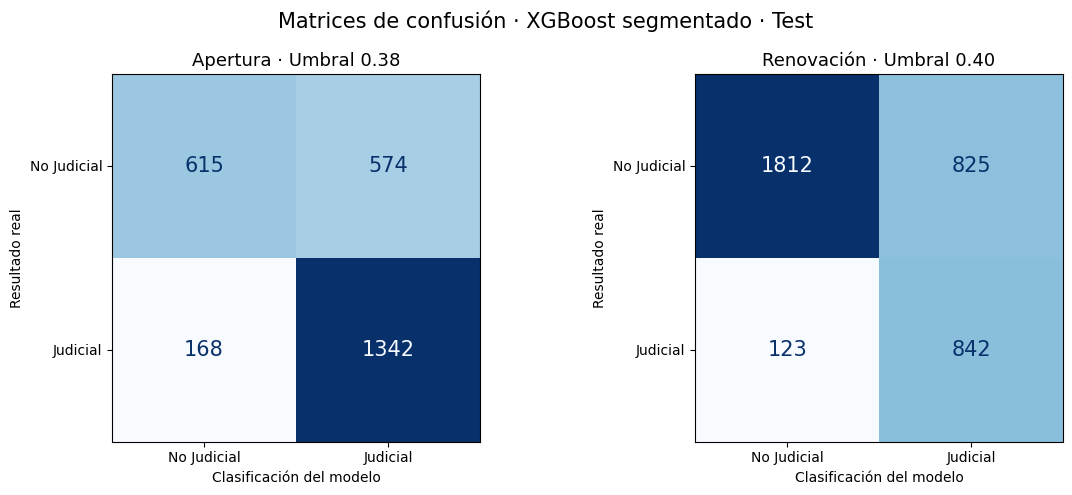

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Representar los mismos conteos ya calculados en la tabla final de Test.
fig_matriz, axes_matriz = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre in zip(axes_matriz, ['Apertura', 'Renovación']):
    fila = tabla_test_comparativo[
        tabla_test_comparativo['Población'].eq(nombre)
        & tabla_test_comparativo['Modelo'].eq('Segmentado final')
    ].iloc[0]
    matriz = np.array([[int(fila['VN']), int(fila['FP'])],
                       [int(fila['FN']), int(fila['VP'])]])
    visual = ConfusionMatrixDisplay(matriz, display_labels=['No Judicial', 'Judicial'])
    visual.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f"{nombre} · Umbral {float(fila['Umbral']):.2f}", fontsize=13)
    ax.set_xlabel('Clasificación del modelo')
    ax.set_ylabel('Resultado real')
    for texto in visual.text_.ravel():
        texto.set_fontsize(15)
fig_matriz.suptitle('Matrices de confusión · XGBoost segmentado · Test', fontsize=15)
fig_matriz.tight_layout()
fig_matriz.savefig(RUTA_BASE.parent / 'MATRICES_CONFUSION_TEST.png', dpi=220, bbox_inches='tight')
plt.show()


### 24.3. Curvas precisión-recall del modelo final en Test

Las curvas utilizan las predicciones finales ya calculadas en Test. Muestran la relación entre precisión y recall al variar el umbral. El punto rojo indica el umbral elegido y la línea punteada, la proporción judicial de Test. PR-AUC se calcula mediante Average Precision, como en las tablas. Esta celda no entrena modelos ni modifica sus configuraciones.


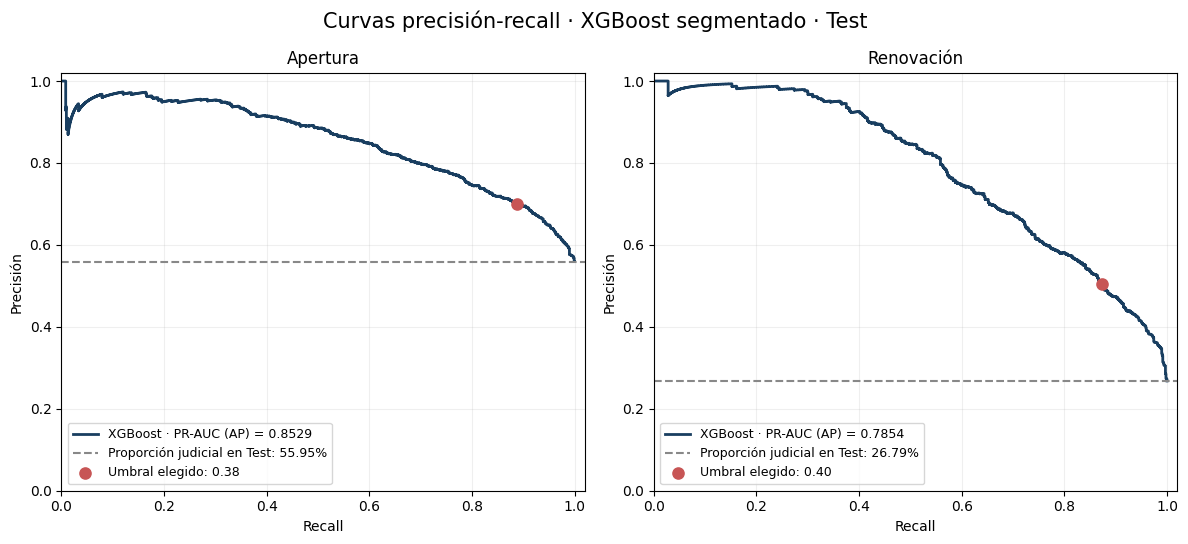

In [ ]:
from sklearn.metrics import precision_recall_curve

# Usar los valores estimados de riesgo del modelo final sobre Test.
fig_pr, axes_pr = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, nombre in zip(axes_pr, ['Apertura', 'Renovación']):
    y_real = divisiones[nombre]['y_test'].to_numpy()
    proba = probabilidades_test_segmentado[nombre]
    umbral = UMBRALES_SEGMENTADOS_FINAL[nombre]
    pred = (proba >= umbral).astype(int)
    precision_curva, recall_curva, _ = precision_recall_curve(y_real, proba)
    ap = average_precision_score(y_real, proba)
    ax.step(recall_curva, precision_curva, where='post', color='#193E60', linewidth=2,
            label=f'XGBoost · PR-AUC (AP) = {ap:.4f}')
    ax.axhline(float(y_real.mean()), color='#888888', linestyle='--',
               label=f'Proporción judicial en Test: {y_real.mean():.2%}')
    ax.scatter(recall_score(y_real, pred), precision_score(y_real, pred),
               color='#C75555', s=65, zorder=4, label=f'Umbral elegido: {umbral:.2f}')
    ax.set(title=nombre, xlabel='Recall', ylabel='Precisión', xlim=(0, 1.02), ylim=(0, 1.02))
    ax.grid(alpha=0.2)
    ax.legend(loc='lower left', fontsize=9)
fig_pr.suptitle('Curvas precisión-recall · XGBoost segmentado · Test', fontsize=15)
fig_pr.tight_layout()
fig_pr.savefig(RUTA_BASE.parent / 'CURVAS_PRECISION_RECALL_TEST.png', dpi=220, bbox_inches='tight')
plt.show()


## 25. Importancia relativa de las variables en la clasificación

Una vez definido XGBoost y su configuración final, se calcula la importancia relativa de las variables utilizadas para clasificar el riesgo de Gestión Judicial. El análisis se presenta por separado para Apertura y Renovación.

Las variables categóricas fueron transformadas mediante One-Hot Encoding durante el entrenamiento. Para facilitar su interpretación, las importancias de todas las categorías se vuelven a agrupar en su variable original. Por ejemplo, las distintas provincias se presentan conjuntamente como `provincia`.




IMPORTANCIA RELATIVA - APERTURA


Variable,Importancia relativa (%),Es historial
Sucursal,29.65 %,No
Provincia,22.05 %,No
Plan de cuotas,12.56 %,No
Score,11.47 %,No
Rango de edad,6.73 %,No
Interés,4.25 %,No
Actividad,2.56 %,No
Relación cuota-ingreso,2.10 %,No
Total facturado,2.02 %,No
Costo del crédito,1.93 %,No


IMPORTANCIA RELATIVA - RENOVACIÓN


Variable,Importancia relativa (%),Es historial
Sucursal,24.70 %,No
Provincia,15.07 %,No
Score,12.08 %,No
Rango de edad,8.68 %,No
Interés,7.29 %,No
Plan de cuotas,6.39 %,No
Judiciales anteriores,5.40 %,Sí
Máxima mora anterior,3.93 %,Sí
Actividad,2.68 %,No
Préstamos anteriores,2.11 %,Sí


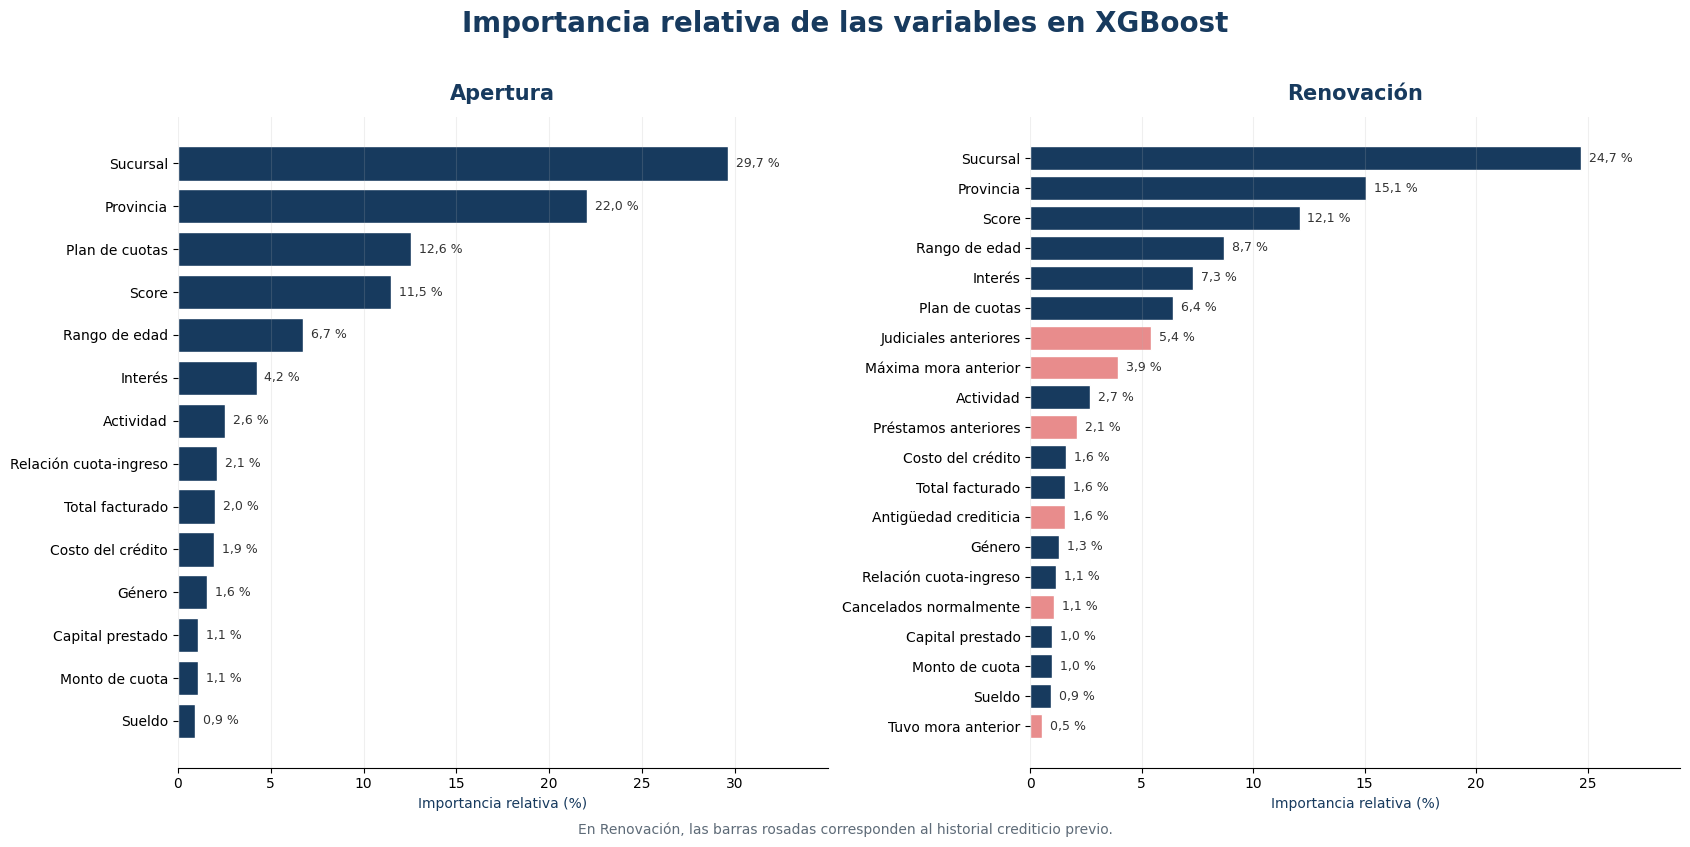

RESUMEN DE IMPORTANCIA POR BLOQUE - RENOVACIÓN


Bloque de variables,Importancia relativa (%)
Historial crediticio previo,14.59 %
Variables del crédito y del solicitante,85.41 %
Total,100.00 %


In [ ]:
# ============================================================
# 25. IMPORTANCIA RELATIVA DE LAS VARIABLES DEL XGBOOST FINAL
# ============================================================

VARIABLES_HISTORICAS_RENOVACION = [
    'antiguedad_credito',
    'cantidad_prestamos_anteriores',
    'tuvo_mora_anterior',
    'max_mora_prestamos_anteriores',
    'prestamos_cancelados_normal',
    'prestamos_en_judicial_anteriores'
]

ETIQUETAS_VARIABLES = {
    'rscore': 'Score',
    'capitalprestado': 'Capital prestado',
    'plan': 'Plan de cuotas',
    'SUELDO': 'Sueldo',
    'interes': 'Interés',
    'totalfac': 'Total facturado',
    'costo_credito': 'Costo del crédito',
    'monto_cuota': 'Monto de cuota',
    'actividad': 'Actividad',
    'rangoedad': 'Rango de edad',
    'genero': 'Género',
    'provincia': 'Provincia',
    'sucursal': 'Sucursal',
    'relacion_cuota_ingreso': 'Relación cuota-ingreso',
    'antiguedad_credito': 'Antigüedad crediticia',
    'cantidad_prestamos_anteriores': 'Préstamos anteriores',
    'tuvo_mora_anterior': 'Tuvo mora anterior',
    'max_mora_prestamos_anteriores': 'Máxima mora anterior',
    'prestamos_cancelados_normal': 'Cancelados normalmente',
    'prestamos_en_judicial_anteriores': 'Judiciales anteriores'
}


def identificar_variable_original(nombre_transformado, variables_originales):
    # Relaciona cada columna transformada con su variable original.
    nombre_limpio = str(nombre_transformado).split('__', 1)[-1]

    # Se ordena por longitud para evitar coincidencias parciales incorrectas.
    for variable in sorted(variables_originales, key=len, reverse=True):
        if nombre_limpio == variable or nombre_limpio.startswith(variable + '_'):
            return variable

    return nombre_limpio


def obtener_importancia_agrupada(modelo_pipeline, poblacion, variables_originales):
    preprocesador = modelo_pipeline.named_steps['pre']
    clasificador = modelo_pipeline.named_steps['modelo']

    nombres_transformados = preprocesador.get_feature_names_out()
    importancias = np.asarray(
        clasificador.feature_importances_,
        dtype=float
    )

    if len(nombres_transformados) != len(importancias):
        raise ValueError(
            f'{poblacion}: no coincide la cantidad de variables '
            'transformadas con las importancias de XGBoost.'
        )

    detalle = pd.DataFrame({
        'Variable transformada': nombres_transformados,
        'Importancia': importancias
    })
    detalle['Variable'] = detalle['Variable transformada'].apply(
        identificar_variable_original,
        variables_originales=variables_originales
    )

    agrupada = (
        detalle.groupby('Variable', as_index=False)['Importancia']
        .sum()
    )

    # Incluir también variables cuya importancia haya resultado igual a cero.
    base_variables = pd.DataFrame({'Variable': variables_originales})
    agrupada = base_variables.merge(
        agrupada,
        on='Variable',
        how='left'
    )
    agrupada['Importancia'] = agrupada['Importancia'].fillna(0.0)

    total = agrupada['Importancia'].sum()
    if total <= 0:
        raise ValueError(
            f'{poblacion}: XGBoost no devolvió importancias válidas.'
        )

    agrupada['Importancia relativa'] = agrupada['Importancia'] / total
    agrupada['Importancia relativa (%)'] = (
        agrupada['Importancia relativa'] * 100
    )
    agrupada['Población'] = poblacion
    agrupada['Variable mostrada'] = agrupada['Variable'].map(
        ETIQUETAS_VARIABLES
    ).fillna(agrupada['Variable'])
    agrupada['Es historial'] = np.where(
        agrupada['Variable'].isin(VARIABLES_HISTORICAS_RENOVACION),
        'Sí',
        'No'
    )

    return agrupada.sort_values(
        'Importancia relativa (%)',
        ascending=False
    ).reset_index(drop=True)


tablas_importancia = []
for nombre in ['Apertura', 'Renovación']:
    tablas_importancia.append(
        obtener_importancia_agrupada(
            modelos_segmentados_test[nombre],
            nombre,
            VARIABLES[nombre]
        )
    )

tabla_importancia_variables = pd.concat(
    tablas_importancia,
    ignore_index=True
)

for nombre in ['Apertura', 'Renovación']:
    print(f'IMPORTANCIA RELATIVA - {nombre.upper()}')
    tabla_mostrar = tabla_importancia_variables[
        tabla_importancia_variables['Población'].eq(nombre)
    ][[
        'Variable mostrada',
        'Importancia relativa (%)',
        'Es historial'
    ]].rename(columns={'Variable mostrada': 'Variable'})

    display(
        tabla_mostrar.style
        .format({'Importancia relativa (%)': '{:.2f} %'})
        .hide(axis='index')
    )


# Gráficos ordenados de mayor a menor, uno para cada población.
fig, axes = plt.subplots(1, 2, figsize=(17, 8))

for ax, nombre in zip(axes, ['Apertura', 'Renovación']):
    grafico = tabla_importancia_variables[
        tabla_importancia_variables['Población'].eq(nombre)
    ].sort_values('Importancia relativa (%)', ascending=True)

    colores = [
        '#E88C8C' if es_historial == 'Sí' else '#173A5E'
        for es_historial in grafico['Es historial']
    ]

    barras = ax.barh(
        grafico['Variable mostrada'],
        grafico['Importancia relativa (%)'],
        color=colores,
        edgecolor='white'
    )

    ax.set_title(
        nombre,
        fontsize=15,
        fontweight='bold',
        color='#173A5E',
        pad=12
    )
    ax.set_xlabel('Importancia relativa (%)', color='#173A5E')
    ax.grid(axis='x', alpha=0.20)
    ax.spines[['top', 'right', 'left']].set_visible(False)

    limite = max(grafico['Importancia relativa (%)'].max() * 1.18, 1)
    ax.set_xlim(0, limite)

    for barra, valor in zip(barras, grafico['Importancia relativa (%)']):
        ax.text(
            barra.get_width() + limite * 0.012,
            barra.get_y() + barra.get_height() / 2,
            f'{valor:.1f} %'.replace('.', ','),
            va='center',
            fontsize=9,
            color='#333333'
        )

fig.suptitle(
    'Importancia relativa de las variables en XGBoost',
    fontsize=20,
    fontweight='bold',
    color='#173A5E',
    y=1.02
)
fig.text(
    0.5,
    -0.01,
    'En Renovación, las barras rosadas corresponden al historial crediticio previo.',
    ha='center',
    fontsize=10,
    color='#5E6B78'
)
plt.tight_layout()
plt.show()


# Resumir el aporte porcentual conjunto de las variables históricas.
importancia_renovacion = tabla_importancia_variables[
    tabla_importancia_variables['Población'].eq('Renovación')
].copy()

porcentaje_historial = importancia_renovacion.loc[
    importancia_renovacion['Es historial'].eq('Sí'),
    'Importancia relativa (%)'
].sum()

tabla_importancia_bloques = pd.DataFrame({
    'Bloque de variables': [
        'Historial crediticio previo',
        'Variables del crédito y del solicitante',
        'Total'
    ],
    'Importancia relativa (%)': [
        porcentaje_historial,
        100 - porcentaje_historial,
        100.0
    ]
})

print('RESUMEN DE IMPORTANCIA POR BLOQUE - RENOVACIÓN')
display(
    tabla_importancia_bloques.style
    .format({'Importancia relativa (%)': '{:.2f} %'})
    .hide(axis='index')
)


## 26. Evaluar el aporte del historial crediticio en Renovación

La importancia relativa muestra cuánto utiliza XGBoost cada variable, pero no permite comprobar por sí sola cuánto mejora el rendimiento del modelo. Por ese motivo se realiza una segunda evaluación exclusivamente para Renovación.

Se compara el modelo final con historial frente a otra versión entrenada sin las seis variables históricas. Se mantienen sin cambios la población, la división Train/Test por cliente, los hiperparámetros, los pesos segmentados, el umbral de 0,40 y la semilla aleatoria. La única diferencia entre las dos versiones es la presencia o ausencia del historial crediticio previo.

Esta prueba permite evaluar específicamente la parte de la hipótesis que sostiene que el historial del cliente aporta información para clasificar el riesgo de derivación a Gestión Judicial. El Test se utiliza únicamente para la comparación final y los resultados no se emplean para volver a ajustar el modelo.


In [ ]:
# ============================================================
# 26. COMPARACIÓN DE RENOVACIÓN CON Y SIN HISTORIAL
# ============================================================

VARIABLES_RENOVACION_SIN_HISTORIAL = [
    variable for variable in VARIABLES['Renovación']
    if variable not in VARIABLES_HISTORICAS_RENOVACION
]

if len(VARIABLES_RENOVACION_SIN_HISTORIAL) != (
    len(VARIABLES['Renovación']) - len(VARIABLES_HISTORICAS_RENOVACION)
):
    raise ValueError(
        'No se retiraron correctamente las variables históricas de Renovación.'
    )


def construir_xgb_segmentado_con_variables(
    nombre,
    variables_modelo,
    datos_referencia
):
    modelo = XGBClassifier(
        scale_pos_weight=1.0,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    pre = construir_preprocesador(
        datos_referencia,
        variables_modelo,
        escalar_numericas=False
    )

    pipe = Pipeline([
        ('pre', pre),
        ('modelo', modelo)
    ])
    pipe.set_params(**MEJORES_PARAMS_XGB_FINOS[nombre])

    return pipe


s_renovacion = divisiones['Renovación']

X_train_renovacion = s_renovacion['X_train'].reset_index(drop=True)
y_train_renovacion = s_renovacion['y_train'].reset_index(drop=True)
X_test_renovacion = s_renovacion['X_test'].reset_index(drop=True)
y_test_renovacion = s_renovacion['y_test'].reset_index(drop=True)

# Los pesos permanecen iguales a los del modelo final con historial.
pesos_train_renovacion = generar_pesos_fila(
    y_train_renovacion.to_numpy(),
    X_train_renovacion['rscore'].to_numpy(),
    PESOS_SEGMENTADOS_FINAL['Renovación']
)

modelo_renovacion_sin_historial = construir_xgb_segmentado_con_variables(
    nombre='Renovación',
    variables_modelo=VARIABLES_RENOVACION_SIN_HISTORIAL,
    datos_referencia=X_train_renovacion
)

modelo_renovacion_sin_historial.fit(
    X_train_renovacion[VARIABLES_RENOVACION_SIN_HISTORIAL],
    y_train_renovacion,
    modelo__sample_weight=pesos_train_renovacion
)

proba_test_con_historial = probabilidades_test_segmentado['Renovación']
proba_test_sin_historial = modelo_renovacion_sin_historial.predict_proba(
    X_test_renovacion[VARIABLES_RENOVACION_SIN_HISTORIAL]
)[:, 1]

umbral_renovacion = UMBRALES_SEGMENTADOS_FINAL['Renovación']
filas_comparacion_historial = []

for version, proba, cantidad_variables in [
    (
        'Con historial',
        proba_test_con_historial,
        len(VARIABLES['Renovación'])
    ),
    (
        'Sin historial',
        proba_test_sin_historial,
        len(VARIABLES_RENOVACION_SIN_HISTORIAL)
    )
]:
    metricas = metricas_en_umbral(
        y_test_renovacion.to_numpy(),
        proba,
        umbral_renovacion
    )

    filas_comparacion_historial.append({
        'Población': 'Renovación',
        'Versión': version,
        'Cantidad de variables': cantidad_variables,
        'Umbral': umbral_renovacion,
        'PR-AUC': average_precision_score(
            y_test_renovacion,
            proba
        ),
        'ROC-AUC': roc_auc_score(
            y_test_renovacion,
            proba
        ),
        **metricas
    })

tabla_historial_vs_sin = pd.DataFrame(filas_comparacion_historial)

metricas_diferencia = [
    'PR-AUC', 'ROC-AUC', 'Precisión', 'Recall',
    'F1', 'F2', 'Exactitud balanceada',
    'VP', 'FN', 'FP', 'VN'
]

con_historial = tabla_historial_vs_sin[
    tabla_historial_vs_sin['Versión'].eq('Con historial')
].iloc[0]
sin_historial = tabla_historial_vs_sin[
    tabla_historial_vs_sin['Versión'].eq('Sin historial')
].iloc[0]

tabla_diferencia_historial = pd.DataFrame({
    'Métrica': metricas_diferencia,
    'Con historial': [con_historial[m] for m in metricas_diferencia],
    'Sin historial': [sin_historial[m] for m in metricas_diferencia],
    'Diferencia (con - sin)': [
        con_historial[m] - sin_historial[m]
        for m in metricas_diferencia
    ]
})

print('COMPARACIÓN FINAL EN TEST - RENOVACIÓN')
display(
    tabla_historial_vs_sin.style
    .format({
        'Umbral': '{:.2f}',
        'PR-AUC': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'Precisión': '{:.2%}',
        'Recall': '{:.2%}',
        'F1': '{:.4f}',
        'F2': '{:.4f}',
        'Exactitud balanceada': '{:.4f}'
    })
    .hide(axis='index')
)

print('DIFERENCIAS PRODUCIDAS POR LA INCORPORACIÓN DEL HISTORIAL')
display(tabla_diferencia_historial)

delta_pr_auc = con_historial['PR-AUC'] - sin_historial['PR-AUC']
delta_recall = con_historial['Recall'] - sin_historial['Recall']
delta_fn = int(con_historial['FN'] - sin_historial['FN'])

print('\nLECTURA AUTOMÁTICA DEL RESULTADO')
print(
    'Variación de PR-AUC al incorporar historial:',
    f'{delta_pr_auc:+.4f}'
)
print(
    'Variación de recall al incorporar historial:',
    f'{delta_recall:+.2%}'
)
print(
    'Variación de falsos negativos al incorporar historial:',
    f'{delta_fn:+d}'
)

if delta_pr_auc > 0:
    print(
        'En esta partición de Test, el historial incrementó el PR-AUC '
        'del modelo de Renovación.'
    )
elif delta_pr_auc < 0:
    print(
        'En esta partición de Test, el historial no incrementó el PR-AUC '
        'del modelo de Renovación.'
    )
else:
    print(
        'En esta partición de Test, ambas versiones obtuvieron el mismo PR-AUC.'
    )


COMPARACIÓN FINAL EN TEST - RENOVACIÓN


Población,Versión,Cantidad de variables,Umbral,PR-AUC,ROC-AUC,Precisión,Recall,F1,F2,Exactitud balanceada,VP,FN,FP,VN
Renovación,Con historial,20,0.40,0.7854,0.8837,50.51%,87.25%,0.6398,0.7617,0.7798,842,123,825,1812
Renovación,Sin historial,14,0.40,0.6470,0.8083,42.49%,84.66%,0.5658,0.7064,0.7136,817,148,1106,1531


DIFERENCIAS PRODUCIDAS POR LA INCORPORACIÓN DEL HISTORIAL


,Métrica,Con historial,Sin historial,Diferencia (con - sin)
0,PR-AUC,0.785440,0.646966,0.138474
1,ROC-AUC,0.883671,0.808284,0.075387
2,Precisión,0.505099,0.424857,0.080242
3,Recall,0.872539,0.846632,0.025907
4,F1,0.639818,0.565789,0.074028
5,F2,0.761715,0.706381,0.055334
6,Exactitud balanceada,0.779842,0.713608,0.066234
7,VP,842.000000,817.000000,25.000000
8,FN,123.000000,148.000000,-25.000000
9,FP,825.000000,1106.000000,-281.000000



LECTURA AUTOMÁTICA DEL RESULTADO
Variación de PR-AUC al incorporar historial: +0.1385
Variación de recall al incorporar historial: +2.59%
Variación de falsos negativos al incorporar historial: -25
En esta partición de Test, el historial incrementó el PR-AUC del modelo de Renovación.


## 27. Exportar las configuraciones y los resultados finales


In [ ]:
RUTA_MEJORA_FINAL = Path(
    '/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/'
    'RESULTADOS_DESARROLLO_MODELO_SEGMENTADO_FINAL.xlsx'
)

with pd.ExcelWriter(
    RUTA_MEJORA_FINAL,
    engine='openpyxl'
) as writer:

    tabla_balance_score.to_excel(
        writer,
        sheet_name='Balance_Score_Train',
        index=False
    )

    tabla_challenger_global.to_excel(
        writer,
        sheet_name='Challenger_OOF_Global',
        index=False
    )

    tabla_challenger_score.to_excel(
        writer,
        sheet_name='Challenger_OOF_Score',
        index=False
    )

    tabla_minigrid.to_excel(
        writer,
        sheet_name='Minigrid_Renov_800',
        index=False
    )

    tabla_config_segmentada_final.to_excel(
        writer,
        sheet_name='Config_Final',
        index=False
    )

    tabla_test_comparativo.to_excel(
        writer,
        sheet_name='Test_V2_vs_Segmentado',
        index=False
    )

    tabla_test_score.to_excel(
        writer,
        sheet_name='Test_por_Score',
        index=False
    )

    tabla_importancia_variables.to_excel(
        writer,
        sheet_name='Importancia_Variables',
        index=False
    )

    tabla_importancia_bloques.to_excel(
        writer,
        sheet_name='Importancia_Bloques',
        index=False
    )

    tabla_historial_vs_sin.to_excel(
        writer,
        sheet_name='Historial_vs_Sin',
        index=False
    )

    tabla_diferencia_historial.to_excel(
        writer,
        sheet_name='Diferencia_Historial',
        index=False
    )

print("Archivo guardado en:")
print(RUTA_MEJORA_FINAL)


Archivo guardado en:
/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/RESULTADOS_DESARROLLO_MODELO_SEGMENTADO_FINAL.xlsx


# Conclusión

Se compararon Regresión Logística, Random Forest y XGBoost con operaciones de 2024–2025 con desenlace conocido. La separación entre Train y Test y las particiones de validación cruzada se realizaron por cliente dentro de cada población.

En **Apertura**, el mayor PR-AUC promedio de validación cruzada correspondió a **XGBoost**, con **0.8524**. En **Renovación**, el mayor PR-AUC promedio de validación cruzada correspondió a **XGBoost**, con **0.7776**.

Se mantuvo el desarrollo de XGBoost y la configuración de pesos y umbrales definida en el código. Los resultados finales en Test fueron:

- **Apertura:** con pesos segmentados se detectaron **1332** casos judiciales y quedaron **183** sin detectar. El recall fue **87.92%** y la precisión, **70.36%**. Con peso general se detectaron 1281 casos y quedaron 234 sin detectar.
- **Renovación:** con pesos segmentados se detectaron **830** casos judiciales y quedaron **114** sin detectar. El recall fue **87.92%** y la precisión, **47.05%**. Con peso general se detectaron 829 casos y quedaron 115 sin detectar.

La curva precisión-recall y las matrices de confusión corresponden a estas mismas predicciones finales de Test. La importancia relativa describe el uso de las variables por XGBoost y no implica una relación de causa y efecto.

La comparación de Renovación con y sin historial, presentada en el apartado anterior, permite evaluar el aporte de los antecedentes internos manteniendo el resto de la configuración. La aplicación a la cartera de 2026 corresponde al código 03.

## 28. Guardar la ejecución completa

Ejecutar al terminar. Cada ejecución se guarda en una carpeta distinta de `EJECUCIONES_CODIGO_02`, dentro de la carpeta del proyecto en Drive. Las particiones se reutilizan, pero volver a entrenar requiere mantener las versiones para comparar los mismos resultados.


In [ ]:
import joblib
import platform
import importlib.metadata
from datetime import datetime, timezone

# Guardar después de terminar las tablas, los gráficos y la exportación.
# Cada ejecución tiene su carpeta: no reemplaza los modelos de una anterior.
fecha_02 = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
carpeta_ejecucion_02 = RUTA_GUARDADO_02 / fecha_02
carpeta_ejecucion_02.mkdir(exist_ok=False)

versiones_02 = {'python': platform.python_version()}
for paquete in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'joblib', 'openpyxl', 'matplotlib']:
    versiones_02[paquete] = importlib.metadata.version(paquete)

nombres_estado_02 = [
    'VARIABLES', 'RANDOM_STATE', 'N_SPLITS_TEST', 'N_SPLITS_CV',
    'divisiones', 'FOLDS_CV', 'PESO_ESTANDAR', 'CONFIG_FINAL',
    'MEJORES_PARAMS_XGB_FINOS', 'PESOS_SEGMENTADOS_FINAL',
    'UMBRALES_SEGMENTADOS_FINAL', 'modelos_segmentados_test',
    'probabilidades_test_segmentado', 'probabilidades_test',
    'VARIABLES_HISTORICAS_RENOVACION', 'modelo_renovacion_sin_historial',
    'proba_test_sin_historial', 'proba_test_con_historial'
]
estado_02 = {nombre: globals()[nombre] for nombre in nombres_estado_02 if nombre in globals()}
estado_02.update({nombre: valor for nombre, valor in list(globals().items())
                  if nombre.startswith('tabla') and isinstance(valor, pd.DataFrame)})
joblib.dump(estado_02, carpeta_ejecucion_02 / 'ejecucion_completa.joblib', compress=3)

# Guardar además un CSV legible con el resultado real y cada predicción de Test.
for nombre, division in divisiones.items():
    datos_test = poblaciones[nombre].iloc[division['idx_test']]
    predicciones = pd.DataFrame({
        'fila_base': datos_test.index.to_numpy(),
        'id_cliente': datos_test['id_cliente'].to_numpy(),
        'judicial_real': division['y_test'].to_numpy(),
        'riesgo_estimado': probabilidades_test_segmentado[nombre],
        'umbral': UMBRALES_SEGMENTADOS_FINAL[nombre]
    })
    predicciones['alerta'] = (predicciones['riesgo_estimado'] >= predicciones['umbral']).astype(int)
    etiqueta = 'apertura' if nombre == 'Apertura' else 'renovacion'
    predicciones.to_csv(carpeta_ejecucion_02 / f'predicciones_test_{etiqueta}.csv', index=False)
    joblib.dump(modelos_segmentados_test[nombre], carpeta_ejecucion_02 / f'modelo_{etiqueta}.joblib', compress=3)

import shutil
for ruta in [RUTA_PARTICIONES_02, RUTA_FOLDS_02]:
    shutil.copy2(ruta, carpeta_ejecucion_02 / ruta.name)

with open(RUTA_BASE, 'rb') as archivo_base_02:
    huella_base_02 = hashlib.file_digest(archivo_base_02, 'sha256').hexdigest()
metadatos_02 = {'fecha_utc': fecha_02, 'versiones': versiones_02,
                'base': RUTA_BASE.name, 'sha256_base': huella_base_02,
                'variables': VARIABLES, 'pesos': PESOS_SEGMENTADOS_FINAL,
                'umbrales': UMBRALES_SEGMENTADOS_FINAL}
escribir_json_02(carpeta_ejecucion_02 / 'metadatos.json', metadatos_02)
(carpeta_ejecucion_02 / 'requirements.txt').write_text(
    '\n'.join(f'{k}=={v}' for k, v in versiones_02.items() if k != 'python') + '\n', encoding='utf-8')
# Actualizar el acceso a la última ejecución solo después de guardar todo.
(RUTA_GUARDADO_02 / 'ultima_ejecucion.txt').write_text(fecha_02, encoding='utf-8')
print('Ejecución guardada en:', carpeta_ejecucion_02)
print('Incluye particiones, modelos, predicciones, tablas y versiones.')


Ejecución guardada en: /content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/EJECUCIONES_CODIGO_02/20261023T162308_635682Z
Incluye particiones, modelos, predicciones, tablas y versiones.


## 29. Recuperar una ejecución sin entrenar

Para recuperar: montar Drive, ejecutar las importaciones iniciales y esta celda con `RECUPERAR_EJECUCION_02 = True`. No ejecutar las celdas de entrenamiento. Después pueden ejecutarse las celdas de matrices y curvas con las predicciones recuperadas. Mantener `False` al ejecutar el notebook completo.


In [ ]:
# Ejecutar SOLO esta celda para recuperar resultados sin volver a entrenar.
# Primero montar Drive y ejecutar la celda de importaciones del comienzo.
RECUPERAR_EJECUCION_02 = False  # Cambiar a True solo para recuperar.
CARPETA_EJECUCION_A_RECUPERAR = ''  # Vacío: recuperar la última ejecución guardada.

if RECUPERAR_EJECUCION_02:
    import json
    import joblib
    import platform
    import importlib.metadata
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from sklearn.metrics import (confusion_matrix, average_precision_score,
                                 precision_score, recall_score)

    raiz_02 = Path('/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/EJECUCIONES_CODIGO_02')
    elegida_02 = CARPETA_EJECUCION_A_RECUPERAR or (raiz_02 / 'ultima_ejecucion.txt').read_text(encoding='utf-8').strip()
    origen_02 = raiz_02 / elegida_02
    meta_02 = json.loads((origen_02 / 'metadatos.json').read_text(encoding='utf-8'))
    actuales_02 = {'python': platform.python_version()}
    for paquete in meta_02['versiones']:
        if paquete != 'python':
            actuales_02[paquete] = importlib.metadata.version(paquete)
    diferencias_02 = {k: {'guardada': v, 'actual': actuales_02.get(k)}
                      for k, v in meta_02['versiones'].items() if actuales_02.get(k) != v}
    if diferencias_02:
        raise RuntimeError('Las versiones difieren de las guardadas. Usar las versiones de metadatos.json / requirements.txt antes de cargar los modelos: ' + str(diferencias_02))
    recuperado_02 = joblib.load(origen_02 / 'ejecucion_completa.joblib')
    globals().update(recuperado_02)
    # Ruta para guardar nuevamente los gráficos, sin necesitar leer la base.
    RUTA_BASE = raiz_02.parent / meta_02['base']
    print('Ejecución recuperada sin entrenar:', origen_02)
    display(tabla_test_comparativo)
else:
    print('Recuperación desactivada: no se modificaron los resultados en memoria.')


Recuperación desactivada: no se modificaron los resultados en memoria.
